In [84]:
import pandas as pd


In [85]:
df = pd.read_csv(
    "Precio_Vivienda.csv",
   
)
df.head()

,CCAA,2025T3_1,2025T2_1,2025T1_1,2024T4_1,2024T3_1,2024T2_1,2024T1_1,2023T4_1,2023T3_1,...,2009T2_4,2009T1_4,2008T4_4,2008T3_4,2008T2_4,2008T1_4,2007T4_4,2007T3_4,2007T2_4,2007T1_4
0,Nacional,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,General,"183,389","178,184","171,296","165,433","162,521","158,083","152,618","148,690","150,273",...,"-3,1","-2,7","-5,4","-2,3","-0,7","-0,4","5,7","6,5","5,3","2,4"
2,Vivienda nueva,"207,214","206,055","200,792","190,368","188,899","183,813","178,899","169,581","171,973",...,"-3,1","-2,4","0,8","2,2","1,6","0,4","9,8","8,2","6,0","2,9"
3,Vivienda segunda mano,"179,657","173,924","166,839","161,605","158,490","154,152","148,616","145,467","146,922",...,"-3,2","-3,0","-10,7","-6,2","-2,7","-1,0","2,4","5,1","4,8","2,0"
4,01 Andalucía,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [86]:
df.rename(columns={
    df.columns[0]: "tipo_vivienda"
}, inplace=True)

df.head()


,tipo_vivienda,2025T3_1,2025T2_1,2025T1_1,2024T4_1,2024T3_1,2024T2_1,2024T1_1,2023T4_1,2023T3_1,...,2009T2_4,2009T1_4,2008T4_4,2008T3_4,2008T2_4,2008T1_4,2007T4_4,2007T3_4,2007T2_4,2007T1_4
0,Nacional,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,General,"183,389","178,184","171,296","165,433","162,521","158,083","152,618","148,690","150,273",...,"-3,1","-2,7","-5,4","-2,3","-0,7","-0,4","5,7","6,5","5,3","2,4"
2,Vivienda nueva,"207,214","206,055","200,792","190,368","188,899","183,813","178,899","169,581","171,973",...,"-3,1","-2,4","0,8","2,2","1,6","0,4","9,8","8,2","6,0","2,9"
3,Vivienda segunda mano,"179,657","173,924","166,839","161,605","158,490","154,152","148,616","145,467","146,922",...,"-3,2","-3,0","-10,7","-6,2","-2,7","-1,0","2,4","5,1","4,8","2,0"
4,01 Andalucía,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [87]:
cols_keep = []
for c in df.columns:
    cols_keep.append(c)
    if c == "2007T1_1":
        break
df = df[cols_keep]

df.columns
# ['ccaa', 'tipo', '2025T3', '2025T2', '2025T1', ...]



Index(['tipo_vivienda', '2025T3_1', '2025T2_1', '2025T1_1', '2024T4_1',
       '2024T3_1', '2024T2_1', '2024T1_1', '2023T4_1', '2023T3_1', '2023T2_1',
       '2023T1_1', '2022T4_1', '2022T3_1', '2022T2_1', '2022T1_1', '2021T4_1',
       '2021T3_1', '2021T2_1', '2021T1_1', '2020T4_1', '2020T3_1', '2020T2_1',
       '2020T1_1', '2019T4_1', '2019T3_1', '2019T2_1', '2019T1_1', '2018T4_1',
       '2018T3_1', '2018T2_1', '2018T1_1', '2017T4_1', '2017T3_1', '2017T2_1',
       '2017T1_1', '2016T4_1', '2016T3_1', '2016T2_1', '2016T1_1', '2015T4_1',
       '2015T3_1', '2015T2_1', '2015T1_1', '2014T4_1', '2014T3_1', '2014T2_1',
       '2014T1_1', '2013T4_1', '2013T3_1', '2013T2_1', '2013T1_1', '2012T4_1',
       '2012T3_1', '2012T2_1', '2012T1_1', '2011T4_1', '2011T3_1', '2011T2_1',
       '2011T1_1', '2010T4_1', '2010T3_1', '2010T2_1', '2010T1_1', '2009T4_1',
       '2009T3_1', '2009T2_1', '2009T1_1', '2008T4_1', '2008T3_1', '2008T2_1',
       '2008T1_1', '2007T4_1', '2007T3_1', '2007T2_1', '200

In [88]:
import re
import unicodedata


# --- 1) Normalizador tolerante a tildes/guiones/espacios ---
def norm(s: str) -> str:
    if s is None:
        return ""
    s = str(s).strip().casefold()
    # quita diacríticos (á -> a, ç -> c, etc.)
    s = unicodedata.normalize("NFKD", s)
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    # unifica guiones y variantes a espacio
    s = re.sub(r"[\-–—_/]+", " ", s)
    # colapsa espacios
    s = re.sub(r"\s+", " ", s).strip()
    return s

# --- 2) Lista blanca EXACTA (pero comparada con normalización) ---
ccaa_headers = [
    "Nacional",
    "01 Andalucía",
    "02 Aragón",
    "03 Asturias",
    "04 Balears",
    "05 Canarias",
    "06 Cantabria",
    "07 Castilla y León",
    "08 Castilla - La Mancha",
    "09 Cataluña",
    "10 Comunitat Valenciana",
    "11 Extremadura",
    "12 Galicia",
    "13 Madrid",
    "14 Murcia",
    "15 Navarra",
    "16 País Vasco",
    "17 Rioja",
    "18 Ceuta",
    "19 Melilla",
]

# set normalizado para comparación rápida
ccaa_norm_set = {norm(x) for x in ccaa_headers}

# opcional: diccionario normalizado -> canónico (para que el nombre final quede bonito/consistente)
ccaa_canonical = {norm(x): x for x in ccaa_headers}

# --- 3) Detecta columnas de valores tipo 2025T3 con posibles sufijos ---
value_cols = [c for c in df.columns if isinstance(c, str) and re.match(r"^\d{4}T[1-4]", c)]

# --- 4) Detecta filas cabecera de CCAA (en tipo_vivienda) ---
tipo_raw = df["tipo_vivienda"].astype(str)
tipo_norm = tipo_raw.map(norm)

is_ccaa_header = tipo_norm.isin(ccaa_norm_set)

# filas "vacías" (cabeceras suelen tener todos los periodos NaN)
is_all_nan_values = df[value_cols].isna().all(axis=1)

# --- 5) Construye la CCAA efectiva desde headers y propaga hacia abajo ---
ccaa_ff = tipo_raw.where(is_ccaa_header).ffill()

# si quieres canónica consistente (p.ej. siempre "08 Castilla - La Mancha"):
ccaa_ff = ccaa_ff.map(lambda x: ccaa_canonical.get(norm(x), x) if pd.notna(x) else x)

# --- 6) Filtra filas reales: quita headers y filas sin datos ---
df = df.loc[~is_ccaa_header & ~is_all_nan_values].copy()

# --- 7) Reescribe tipo_vivienda = "<tipo>_<ccaa>" (sin columna nueva final) ---
def slug(s: str) -> str:
    return norm(s).replace(" ", "_")

df["tipo_vivienda"] = (
    df["tipo_vivienda"].map(slug)
    + "_"
    + ccaa_ff.loc[df.index].map(lambda x: slug(re.sub(r"^\d{2}\s*", "", str(x))))
)

In [89]:
tipo_vivienda= df["tipo_vivienda"]

In [90]:
period_cols = [c for c in df.columns if "T" in str(c)]
#2025T1.1

In [91]:
df_model = df.dropna(subset=period_cols, how="all")
df_model.head()

,tipo_vivienda,2025T3_1,2025T2_1,2025T1_1,2024T4_1,2024T3_1,2024T2_1,2024T1_1,2023T4_1,2023T3_1,...,2009T2_1,2009T1_1,2008T4_1,2008T3_1,2008T2_1,2008T1_1,2007T4_1,2007T3_1,2007T2_1,2007T1_1
1,general_nacional,"183,389","178,184","171,296","165,433","162,521","158,083","152,618","148,690","150,273",...,"138,082","138,693","142,511","147,134","149,618","150,082","150,640","151,719","150,103","145,935"
2,vivienda_nueva_nacional,"207,214","206,055","200,792","190,368","188,899","183,813","178,899","169,581","171,973",...,"131,365","132,281","135,526","137,382","136,652","134,966","134,449","132,475","129,748","125,956"
3,vivienda_segunda_mano_nacional,"179,657","173,924","166,839","161,605","158,490","154,152","148,616","145,467","146,922",...,"142,616","142,815","147,259","154,722","160,557","163,288","164,973","169,259","168,847","164,358"
5,general_andalucia,"182,372","177,504","170,858","165,457","162,275","156,273","149,880","145,927","146,784",...,"130,679","130,500","131,847","135,361","135,178","135,751","135,785","133,943","130,901","127,081"
6,vivienda_nueva_andalucia,"221,148","218,247","212,796","203,521","201,651","188,391","184,535","173,254","177,265",...,"121,007","121,762","121,632","123,127","120,303","119,352","119,087","115,067","111,404","108,320"


In [92]:
period_cols = sorted(period_cols, reverse=True)
period_cols[:15] #T2025-2024



['2025T3_1',
 '2025T2_1',
 '2025T1_1',
 '2024T4_1',
 '2024T3_1',
 '2024T2_1',
 '2024T1_1',
 '2023T4_1',
 '2023T3_1',
 '2023T2_1',
 '2023T1_1',
 '2022T4_1',
 '2022T3_1',
 '2022T2_1',
 '2022T1_1']

In [93]:
# Verificar columnas disponibles en df
print("Columnas en df:")
print(df.columns.tolist())
print(f"\nTotal de columnas: {len(df.columns)}")

# Mostrar solo las primeras 20 para ver el patrón
print(f"\nPrimeras 20 columnas: {df.columns.tolist()[:20]}")

Columnas en df:
['tipo_vivienda', '2025T3_1', '2025T2_1', '2025T1_1', '2024T4_1', '2024T3_1', '2024T2_1', '2024T1_1', '2023T4_1', '2023T3_1', '2023T2_1', '2023T1_1', '2022T4_1', '2022T3_1', '2022T2_1', '2022T1_1', '2021T4_1', '2021T3_1', '2021T2_1', '2021T1_1', '2020T4_1', '2020T3_1', '2020T2_1', '2020T1_1', '2019T4_1', '2019T3_1', '2019T2_1', '2019T1_1', '2018T4_1', '2018T3_1', '2018T2_1', '2018T1_1', '2017T4_1', '2017T3_1', '2017T2_1', '2017T1_1', '2016T4_1', '2016T3_1', '2016T2_1', '2016T1_1', '2015T4_1', '2015T3_1', '2015T2_1', '2015T1_1', '2014T4_1', '2014T3_1', '2014T2_1', '2014T1_1', '2013T4_1', '2013T3_1', '2013T2_1', '2013T1_1', '2012T4_1', '2012T3_1', '2012T2_1', '2012T1_1', '2011T4_1', '2011T3_1', '2011T2_1', '2011T1_1', '2010T4_1', '2010T3_1', '2010T2_1', '2010T1_1', '2009T4_1', '2009T3_1', '2009T2_1', '2009T1_1', '2008T4_1', '2008T3_1', '2008T2_1', '2008T1_1', '2007T4_1', '2007T3_1', '2007T2_1', '2007T1_1']

Total de columnas: 76

Primeras 20 columnas: ['tipo_vivienda', '2

In [94]:
import re

# Filtrar solo columnas con sufijo _1
index_cols_1 = [c for c in df.columns if re.fullmatch(r"\d{4}T[1-4]_1", str(c))]
print(f"Columnas con sufijo _1 encontradas: {len(index_cols_1)}")

# Convertir formato numérico español a anglosajón
df_temp = df[["tipo_vivienda"] + index_cols_1].copy()
for col in index_cols_1:
    df_temp[col] = (
        df_temp[col]
        .astype(str)
        .str.replace(".", "", regex=False)  # Eliminar separadores de miles
        .str.replace(",", ".", regex=False)  # Convertir decimal español a anglosajón
        .replace(r"^\s*$", pd.NA, regex=True)  # Espacios vacíos a NA
    )
    df_temp[col] = pd.to_numeric(df_temp[col], errors="coerce")

# Renombrar columnas quitando el sufijo _1
rename_dict = {col: col.replace('_1', '') for col in index_cols_1}
df_grouped = df_temp.rename(columns=rename_dict)

# Crear diccionario de trimestres para usar después
quarter_groups = {col.replace('_1', ''): [col] for col in index_cols_1}

# Filtrar columnas: mantener solo desde 2007T1 en adelante (excluir datos anteriores)
cols_keep = ['tipo_vivienda']
for c in df_grouped.columns:
    if c == 'tipo_vivienda':
        continue
    if c == "2007T1":
        cols_keep.append(c)
        break
    cols_keep.append(c)

# Mantener solo las columnas seleccionadas
df_grouped = df_grouped[cols_keep]
print(f"Columnas después de filtrar (desde 2007T1): {len(df_grouped.columns) - 1}")

# Trabajar con los trimestres sin sufijo
index_cols = sorted([col.replace('_1', '') for col in index_cols_1 if col.replace('_1', '') in cols_keep], reverse=True)
target = index_cols[0]
features = index_cols[1:15]

print(f"Trimestres a usar: {len(index_cols)}")
print(f"Ejemplo: {index_cols[:5]}")

df_model = df_grouped[["tipo_vivienda"] + features + [target]].copy()
df_model = df_model.dropna()

if len(df_model) > 0:
    id_df = df_model[["tipo_vivienda"]].copy()
    X = df_model[features]
    y = df_model[target]
    print(f"✓ Datos listos para el modelo")
    print(f"Forma de X: {X.shape}")
    print(f"Forma de y: {y.shape}")
    print(f"\nPrimeros trimestres: {features[:5]}")
    print(f"Target (último trimestre): {target}")
    print(f"\nPrimeros valores de y:")
    print(y.head())
else:
    print("⚠️ ADVERTENCIA: df_model está vacío después de dropna()")

Columnas con sufijo _1 encontradas: 75
Columnas después de filtrar (desde 2007T1): 75
Trimestres a usar: 75
Ejemplo: ['2025T3', '2025T2', '2025T1', '2024T4', '2024T3']
✓ Datos listos para el modelo
Forma de X: (56, 14)
Forma de y: (56,)

Primeros trimestres: ['2025T2', '2025T1', '2024T4', '2024T3', '2024T2']
Target (último trimestre): 2025T3

Primeros valores de y:
1    183.389
2    207.214
3    179.657
5    182.372
6    221.148
Name: 2025T3, dtype: float64


In [95]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
   test_size=0.2,
    shuffle=False
)


In [96]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [97]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_test_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_test_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
r2 = r2_score(y_test, y_test_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)


MAE: 1.1714851239989674
RMSE: 1.302086897350972
R2: 0.9941430259366877


In [98]:
# Instalar librerías necesarias para Prophet y ARIMA
import sys
import subprocess

print("Instalando prophet y statsmodels...")
subprocess.check_call([sys.executable, "-m", "pip", "install", "prophet", "statsmodels", "--quiet"])
print("✅ Librerías instaladas correctamente")

Instalando prophet y statsmodels...
✅ Librerías instaladas correctamente


In [99]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import r2_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

print("🏠 PREDICCIÓN DE PRECIOS DE VIVIENDA 2025 T4 y 2026 T1")
print("   Modelo: ARIMA (1,1,1)")

all_results = id_df.copy()
all_results["y_real_2025T3"] = y.values

# Almacenar predicciones
all_results["y_pred_2025T4"] = 0.0
all_results["y_pred_2026T1"] = 0.0

# Listas para métricas
r2_arima_list = []
mae_arima_list = []

for idx in range(len(id_df)):
    tipo_vivienda = id_df.iloc[idx]['tipo_vivienda']
    

    # Obtener serie temporal histórica (invertir orden: más antiguo → más reciente)
    fila_datos = df_grouped[df_grouped['tipo_vivienda'] == tipo_vivienda]
    
    if len(fila_datos) == 0:
        continue
    
    # Extraer valores en orden cronológico correcto (invertir index_cols)
    serie_historica = fila_datos[index_cols[::-1]].values.flatten()
    
    # Eliminar NaN al inicio y final
    serie_limpia = pd.Series(serie_historica).dropna()
    
    if len(serie_limpia) < 10:  # Necesitamos suficientes datos
        continue
    
    # ========== MODELO: ARIMA ==========
    try:
        # ARIMA con orden (1,1,1)
        modelo_arima = ARIMA(serie_limpia.values, order=(1, 1, 1))
        resultado_arima = modelo_arima.fit()
        
        # Predecir 2 pasos adelante
        forecast_arima = resultado_arima.forecast(steps=2)
        
        pred_2025t4_arima = forecast_arima[0]
        pred_2026t1_arima = forecast_arima[1]
        
        all_results.loc[all_results.index[idx], "y_pred_2025T4"] = pred_2025t4_arima
        all_results.loc[all_results.index[idx], "y_pred_2026T1"] = pred_2026t1_arima
        
        # Calcular métricas (sobre datos de entrenamiento)
        fitted_values = resultado_arima.fittedvalues
        if len(fitted_values) > 0:
            # ARIMA con d=1 pierde el primer valor
            valores_reales = serie_limpia.values[1:len(fitted_values)+1]
            if len(valores_reales) == len(fitted_values):
                r2_a = r2_score(valores_reales, fitted_values)
                mae_a = mean_absolute_error(valores_reales, fitted_values)
                
                r2_arima_list.append(r2_a)
                mae_arima_list.append(mae_a)
        
    except Exception as e:
        # En caso de error, usar último valor conocido
        all_results.loc[all_results.index[idx], "y_pred_2025T4"] = serie_limpia.iloc[-1]
        all_results.loc[all_results.index[idx], "y_pred_2026T1"] = serie_limpia.iloc[-1]

# Calcular métricas promedio
r2_arima = sum(r2_arima_list) / len(r2_arima_list) if r2_arima_list else 0
mae_arima = sum(mae_arima_list) / len(mae_arima_list) if mae_arima_list else 0

print("\n" + "="*90)
print("📊 MÉTRICAS DEL MODELO ARIMA:")
print("="*90)
print(f"\n  R²  promedio: {r2_arima:.4f}")
print(f"  MAE promedio: {mae_arima:.4f}")
print(f"  Modelos exitosos: {len(r2_arima_list)}/{len(id_df)}")

print("\n" + "="*90)
print(f"✅ Predicciones generadas para {len(all_results)} tipos de vivienda")
print("="*90)

# Mostrar comparación para nivel nacional
print("\n📋 COMPARACIÓN NACIONAL:")
print("-" * 90)
nacional_sample = all_results[all_results['tipo_vivienda'].str.contains('nacional')]
for _, row in nacional_sample.iterrows():
    tipo = row['tipo_vivienda'].replace('_nacional', '').replace('_', ' ').title()[:40]
    var_t4 = ((row['y_pred_2025T4']-row['y_real_2025T3'])/row['y_real_2025T3']*100)
    var_t1 = ((row['y_pred_2026T1']-row['y_real_2025T3'])/row['y_real_2025T3']*100)
    var_trim = ((row['y_pred_2026T1']-row['y_pred_2025T4'])/row['y_pred_2025T4']*100)
    
    print(f"\n  {tipo}:")
    print(f"    2025T3 (real):    {row['y_real_2025T3']:>8.2f}")
    print(f"    2025T4 (ARIMA):   {row['y_pred_2025T4']:>8.2f}  [{var_t4:>+5.2f}% vs T3]")
    print(f"    2026T1 (ARIMA):   {row['y_pred_2026T1']:>8.2f}  [{var_t1:>+5.2f}% vs T3]")
    print(f"    Crecimiento trimestral T4→T1: {var_trim:>+5.2f}%")

print("\n" + "="*90)

all_results

🏠 PREDICCIÓN DE PRECIOS DE VIVIENDA 2025 T4 y 2026 T1
   Modelo: ARIMA (1,1,1)

📊 MÉTRICAS DEL MODELO ARIMA:

  R²  promedio: 0.0000
  MAE promedio: 0.0000
  Modelos exitosos: 0/56

✅ Predicciones generadas para 56 tipos de vivienda

📋 COMPARACIÓN NACIONAL:
------------------------------------------------------------------------------------------

  General:
    2025T3 (real):      183.39
    2025T4 (ARIMA):     188.17  [+2.61% vs T3]
    2026T1 (ARIMA):     192.69  [+5.07% vs T3]
    Crecimiento trimestral T4→T1: +2.40%

  Vivienda Nueva:
    2025T3 (real):      207.21
    2025T4 (ARIMA):     211.00  [+1.83% vs T3]
    2026T1 (ARIMA):     214.68  [+3.60% vs T3]
    Crecimiento trimestral T4→T1: +1.74%

  Vivienda Segunda Mano:
    2025T3 (real):      179.66
    2025T4 (ARIMA):     184.40  [+2.64% vs T3]
    2026T1 (ARIMA):     188.73  [+5.05% vs T3]
    Crecimiento trimestral T4→T1: +2.35%



,tipo_vivienda,y_real_2025T3,y_pred_2025T4,y_pred_2026T1
1,general_nacional,183.389,188.170017,192.689039
2,vivienda_nueva_nacional,207.214,211.002165,214.683519
3,vivienda_segunda_mano_nacional,179.657,184.399361,188.725870
5,general_andalucia,182.372,187.106544,191.654874
6,vivienda_nueva_andalucia,221.148,225.956626,230.684741
7,vivienda_segunda_mano_andalucia,177.324,181.788058,185.950642
9,general_aragon,176.563,202.287921,204.816949
10,vivienda_nueva_aragon,188.999,229.044266,230.251116
11,vivienda_segunda_mano_aragon,173.041,200.686462,204.440471
13,general_aragon,162.381,202.287921,204.816949


In [100]:
import re

# Usar los trimestres agrupados (sin sufijos _1, _2)
period_cols = sorted([q for q in quarter_groups.keys()])
print(f"Columnas de trimestres agrupados: {len(period_cols)}")
print(f"Primeras 15: {period_cols[:15]}")

# Crear df_kpi con los datos agrupados por trimestre
df_kpi = df_grouped[["tipo_vivienda"] + period_cols].copy()

Columnas de trimestres agrupados: 75
Primeras 15: ['2007T1', '2007T2', '2007T3', '2007T4', '2008T1', '2008T2', '2008T3', '2008T4', '2009T1', '2009T2', '2009T3', '2009T4', '2010T1', '2010T2', '2010T3']


**KPIS**
**1. Variación interanual Índice Precio Vivienda**

In [101]:
# df_kpi ya fue creado en la celda anterior con df_grouped

df_yoy = df_kpi.copy()
df_yoy[period_cols] = df_kpi[period_cols].pct_change(axis=1, periods=4) * 100

In [102]:
df_yoy_long = df_yoy.melt(
    id_vars="tipo_vivienda",
    value_vars=period_cols,
    var_name="period",
    value_name="yoy_pct"
)

df_yoy_long = df_yoy_long.dropna()

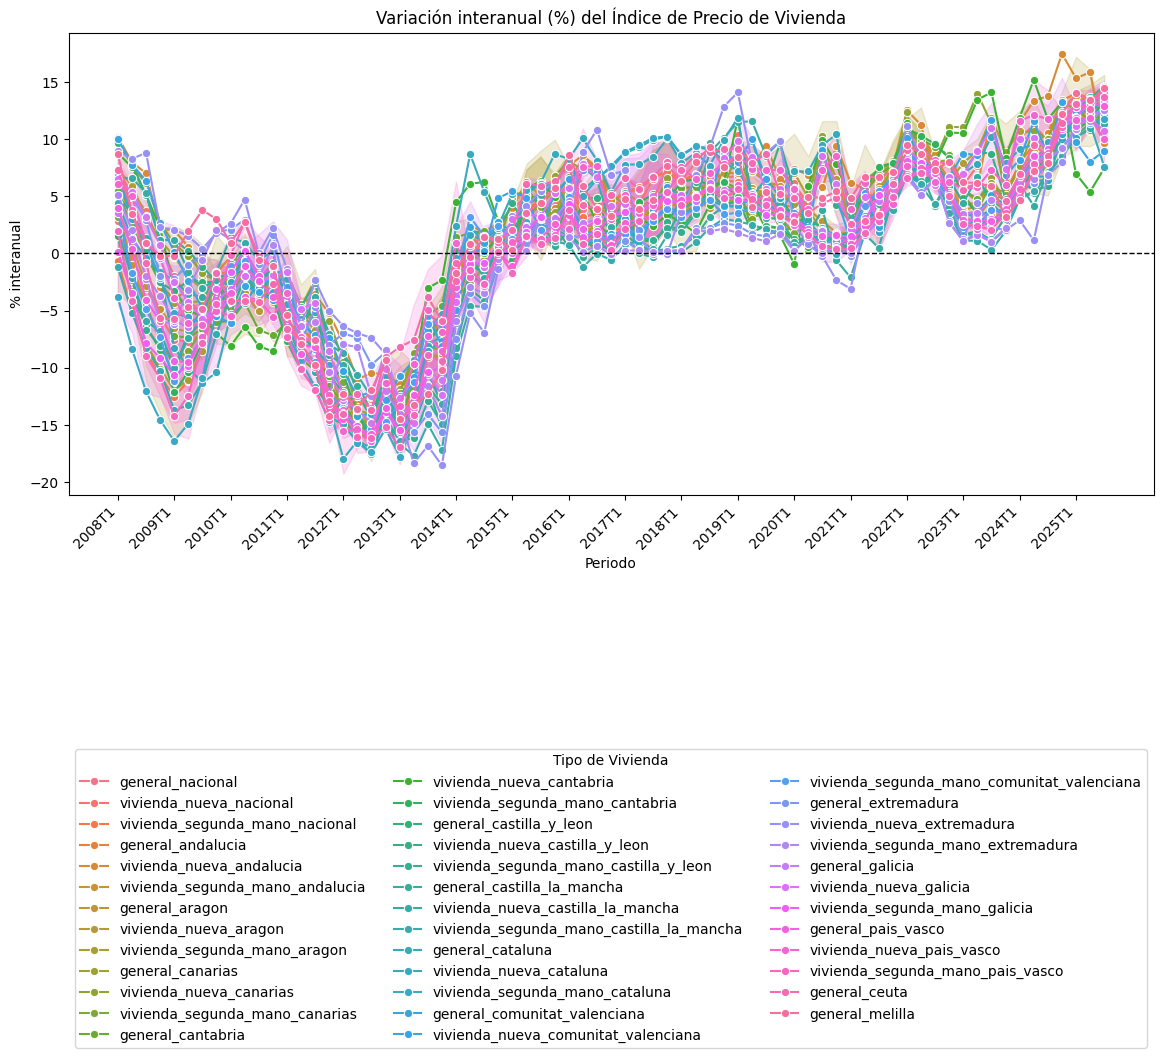

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14,6))

sns.lineplot(
    data=df_yoy_long,
    x="period",
    y="yoy_pct",
    hue="tipo_vivienda",
    marker="o"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Variación interanual (%) del Índice de Precio de Vivienda")
plt.ylabel("% interanual")
plt.xlabel("Periodo")

# Mostrar solo años (T1) en el eje X
periodos_unicos = df_yoy_long['period'].unique()
etiquetas_t1 = [p for p in periodos_unicos if 'T1' in str(p)]
plt.xticks(ticks=range(0, len(periodos_unicos), 4), labels=etiquetas_t1[::1], rotation=45, ha='right')

plt.legend(
    title="Tipo de Vivienda",
    bbox_to_anchor=(0.5, -0.55),
    loc="upper center",
    ncol=3,
    borderaxespad=0
)

plt.tight_layout()
plt.show()

**2. Ranking CCAA por Precio Medio Actual**

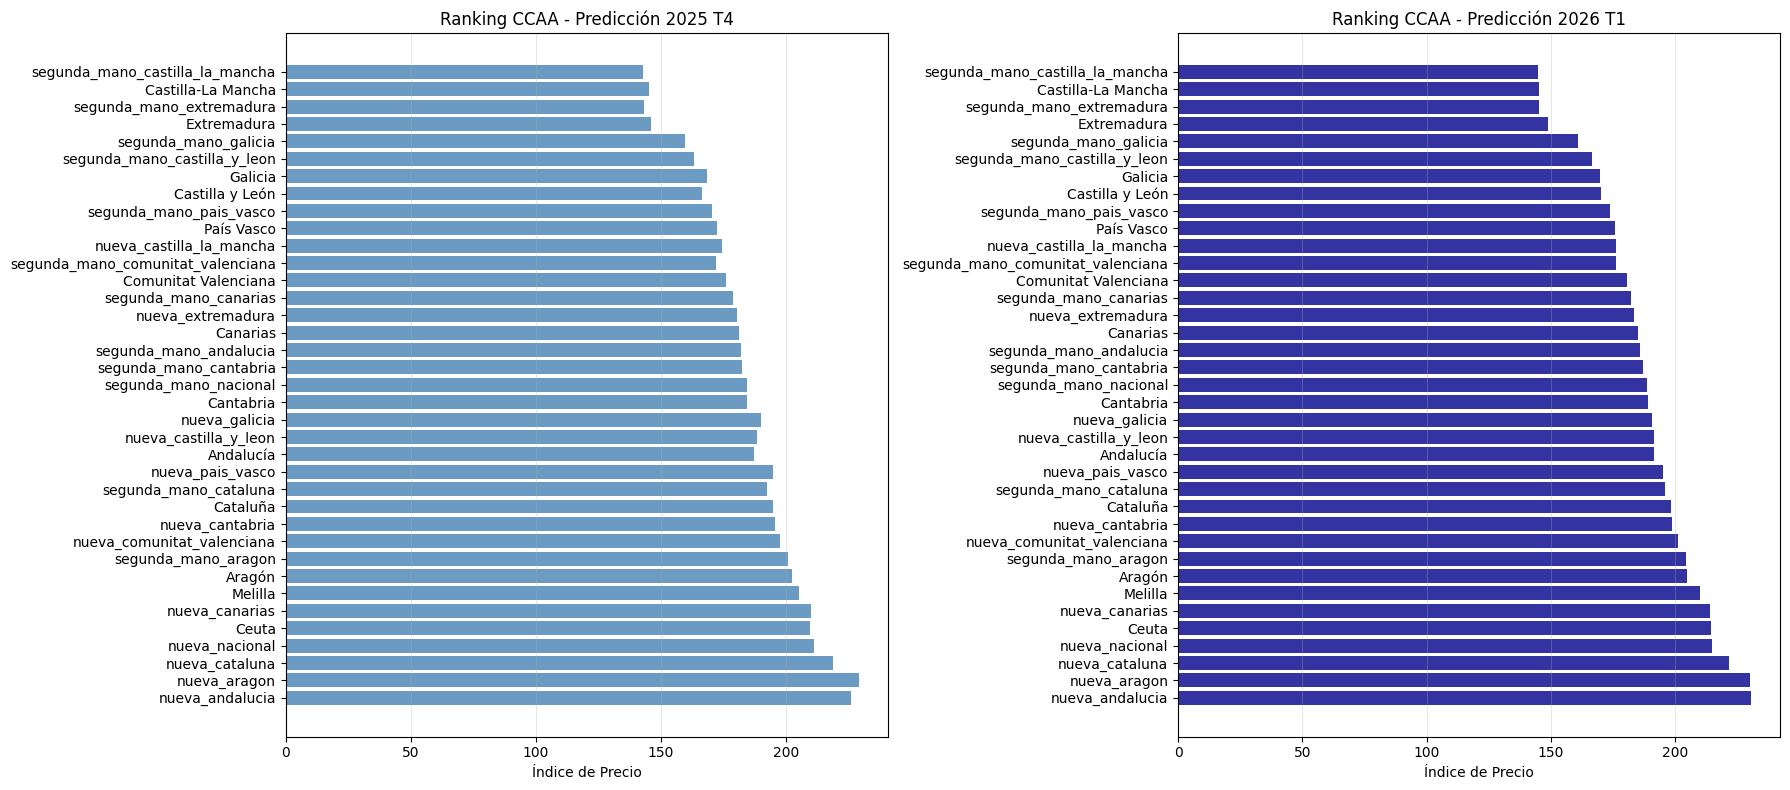


Top 5 CCAA más caras (predicción 2026 T1):
nueva_andalucia          : 2025T4=  225.96 | 2026T1=  230.68 [+4.31%]
nueva_aragon             : 2025T4=  229.04 | 2026T1=  230.25 [+15.49%]
nueva_cataluna           : 2025T4=  218.53 | 2026T1=  221.52 [+2.83%]
nueva_nacional           : 2025T4=  211.00 | 2026T1=  214.68 [+3.60%]
Ceuta                    : 2025T4=  209.51 | 2026T1=  214.30 [+4.74%]

Top 5 CCAA más baratas (predicción 2026 T1):
segunda_mano_galicia     : 2025T4=  159.42 | 2026T1=  161.07 [-5.24%]
Extremadura              : 2025T4=  146.15 | 2026T1=  148.85 [+3.91%]
segunda_mano_extremadura : 2025T4=  143.09 | 2026T1=  145.32 [+3.26%]
Castilla-La Mancha       : 2025T4=  145.06 | 2026T1=  145.05 [-0.01%]
segunda_mano_castilla_la_mancha: 2025T4=  142.61 | 2026T1=  144.90 [+3.40%]


In [104]:
# Extraer CCAA de tipo_vivienda
def extract_ccaa(tipo_vivienda):
    # El formato es "tipo_ccaa"
    parts = tipo_vivienda.split('_')
    # Tomar las últimas partes como CCAA (puede haber guiones bajos)
    # Buscar la última parte que parece CCAA
    if len(parts) >= 2:
        return '_'.join(parts[1:])  # Todo después del primer guion bajo
    return tipo_vivienda

all_results['ccaa'] = all_results['tipo_vivienda'].apply(extract_ccaa)

# Diccionario para nombres bonitos
ccaa_pretty = {
    "nacional": "Nacional",
    "andalucia": "Andalucía",
    "aragon": "Aragón",
    "asturias": "Asturias",
    "balears": "Illes Balears",
    "canarias": "Canarias",
    "cantabria": "Cantabria",
    "castilla_y_leon": "Castilla y León",
    "castilla_la_mancha": "Castilla-La Mancha",
    "cataluna": "Cataluña",
    "comunitat_valenciana": "Comunitat Valenciana",
    "extremadura": "Extremadura",
    "galicia": "Galicia",
    "madrid": "Madrid",
    "murcia": "Murcia",
    "navarra": "Navarra",
    "pais_vasco": "País Vasco",
    "rioja": "La Rioja",
    "ceuta": "Ceuta",
    "melilla": "Melilla"
}

# Promediar por CCAA (todas las tipologías de vivienda)
ranking_ccaa = all_results.groupby('ccaa').agg({
    'y_real_2025T3': 'mean',
    'y_pred_2025T4': 'mean',
    'y_pred_2026T1': 'mean'
}).reset_index()

ranking_ccaa['ccaa_nombre'] = ranking_ccaa['ccaa'].map(ccaa_pretty).fillna(ranking_ccaa['ccaa'])
ranking_ccaa['cambio_2025T4'] = ((ranking_ccaa['y_pred_2025T4'] - ranking_ccaa['y_real_2025T3']) / ranking_ccaa['y_real_2025T3'] * 100)
ranking_ccaa['cambio_2026T1'] = ((ranking_ccaa['y_pred_2026T1'] - ranking_ccaa['y_real_2025T3']) / ranking_ccaa['y_real_2025T3'] * 100)
ranking_ccaa = ranking_ccaa[ranking_ccaa['ccaa'] != 'nacional'].sort_values('y_pred_2026T1', ascending=False)

# Visualización
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

# Gráfico 1: Predicción 2025T4
ax1.barh(ranking_ccaa['ccaa_nombre'], ranking_ccaa['y_pred_2025T4'], color='steelblue', alpha=0.8)
ax1.set_xlabel('Índice de Precio')
ax1.set_ylabel('')
ax1.set_title('Ranking CCAA - Predicción 2025 T4')
ax1.grid(axis='x', alpha=0.3)

# Gráfico 2: Predicción 2026T1
ax2.barh(ranking_ccaa['ccaa_nombre'], ranking_ccaa['y_pred_2026T1'], color='darkblue', alpha=0.8)
ax2.set_xlabel('Índice de Precio')
ax2.set_ylabel('')
ax2.set_title('Ranking CCAA - Predicción 2026 T1')
ax2.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("\nTop 5 CCAA más caras (predicción 2026 T1):")
for i, row in ranking_ccaa.head(5).iterrows():
    print(f"{row['ccaa_nombre']:25s}: 2025T4={row['y_pred_2025T4']:>8.2f} | 2026T1={row['y_pred_2026T1']:>8.2f} [{row['cambio_2026T1']:>+5.2f}%]")
    
print("\nTop 5 CCAA más baratas (predicción 2026 T1):")
for i, row in ranking_ccaa.tail(5).iterrows():
    print(f"{row['ccaa_nombre']:25s}: 2025T4={row['y_pred_2025T4']:>8.2f} | 2026T1={row['y_pred_2026T1']:>8.2f} [{row['cambio_2026T1']:>+5.2f}%]")


**3. Evolución Temporal por Tipo de Vivienda (Nacional)**

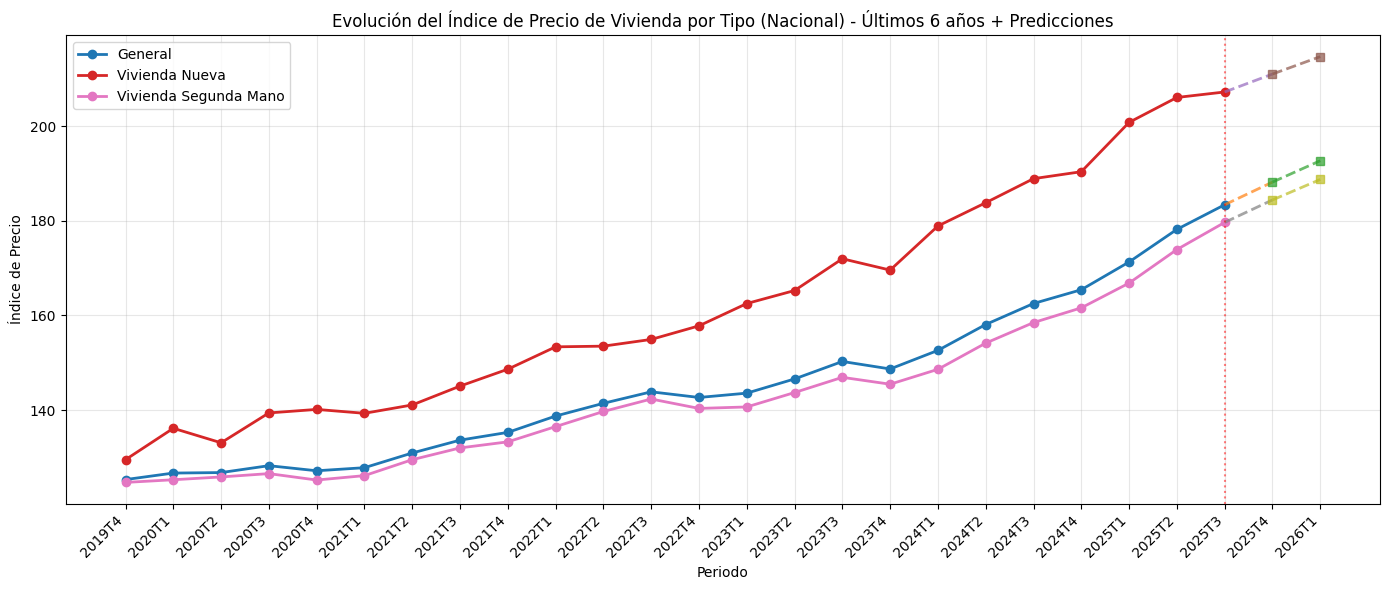


Índices 2025T3 (actual) y predicciones futuras (Nacional):
------------------------------------------------------------------------------------------
General                       :
  2025T3 (real):       183.39
  2025T4 (ARIMA):      188.17 [ +2.61%]
  2026T1 (ARIMA):      192.69 [ +5.07%]
Vivienda Nueva                :
  2025T3 (real):       207.21
  2025T4 (ARIMA):      211.00 [ +1.83%]
  2026T1 (ARIMA):      214.68 [ +3.60%]
Vivienda Segunda Mano         :
  2025T3 (real):       179.66
  2025T4 (ARIMA):      184.40 [ +2.64%]
  2026T1 (ARIMA):      188.73 [ +5.05%]


In [105]:
# Filtrar solo nivel nacional - capturar los tres tipos de vivienda
df_nacional = df_kpi[
    df_kpi['tipo_vivienda'].str.contains('_nacional')
].copy()

# Extraer tipo de vivienda correctamente
def extract_tipo(tipo_vivienda):
    if tipo_vivienda.startswith('vivienda_nueva_'):
        return 'vivienda_nueva'
    elif tipo_vivienda.startswith('vivienda_segunda_mano_') or tipo_vivienda.startswith('vivienda_de_segunda_mano_'):
        return 'vivienda_segunda_mano'
    elif tipo_vivienda.startswith('vivienda_') and not tipo_vivienda.startswith('vivienda_nueva') and not tipo_vivienda.startswith('vivienda_segunda'):
        return 'vivienda'
    elif tipo_vivienda.startswith('general_'):
        return 'general'
    else:
        return tipo_vivienda.split('_')[0]

df_nacional['tipo'] = df_nacional['tipo_vivienda'].apply(extract_tipo)

# Agrupar para evitar duplicados
df_nacional = df_nacional.groupby(['tipo_vivienda', 'tipo'], as_index=False)[period_cols].sum()

# Nombres bonitos para tipos
tipo_nombres = {
    'vivienda': 'Vivienda en General',
    'vivienda_nueva': 'Vivienda Nueva',
    'vivienda_segunda_mano': 'Vivienda Segunda Mano',
    'general': 'General'
}

# Transformar a formato largo
df_nacional_long = df_nacional.melt(
    id_vars=['tipo_vivienda', 'tipo'],
    value_vars=period_cols,
    var_name='periodo',
    value_name='precio'
)

df_nacional_long['tipo_nombre'] = df_nacional_long['tipo'].map(tipo_nombres).fillna(df_nacional_long['tipo'])

# Seleccionar últimos 24 trimestres (6 años) + predicciones
periodos_recientes = sorted(period_cols)[-24:]
df_plot = df_nacional_long[df_nacional_long['periodo'].isin(periodos_recientes)]

# Agregar predicciones 2025T4 y 2026T1 al gráfico
predicciones = []
for tipo in df_nacional['tipo'].unique():
    tipo_data = all_results[all_results['tipo_vivienda'].str.startswith(tipo + '_nacional')]
    tipo_data = tipo_data.groupby('tipo_vivienda', as_index=False).agg({
        'y_pred_2025T4': 'sum',
        'y_pred_2026T1': 'sum'
    })
    
    if len(tipo_data) > 0:
        tipo_nombre = tipo_nombres.get(tipo, tipo)
        
        # Agregar 2025T4
        predicciones.append({
            'tipo_vivienda': tipo_data['tipo_vivienda'].values[0],
            'tipo': tipo,
            'periodo': '2025T4',
            'precio': tipo_data['y_pred_2025T4'].values[0],
            'tipo_nombre': tipo_nombre
        })
        
        # Agregar 2026T1
        predicciones.append({
            'tipo_vivienda': tipo_data['tipo_vivienda'].values[0],
            'tipo': tipo,
            'periodo': '2026T1',
            'precio': tipo_data['y_pred_2026T1'].values[0],
            'tipo_nombre': tipo_nombre
        })

# Concatenar predicciones con datos históricos
df_predicciones = pd.DataFrame(predicciones)
df_plot_completo = pd.concat([df_plot, df_predicciones], ignore_index=True)

# Ordenar para que las líneas se dibujen correctamente
df_plot_completo['periodo_sort'] = pd.Categorical(
    df_plot_completo['periodo'],
    categories=periodos_recientes + ['2025T4', '2026T1'],
    ordered=True
)
df_plot_completo = df_plot_completo.sort_values(['tipo_nombre', 'periodo_sort'])

# Visualización
plt.figure(figsize=(14, 6))
for tipo in df_plot_completo['tipo_nombre'].unique():
    data = df_plot_completo[df_plot_completo['tipo_nombre'] == tipo]
    
    # Separar datos históricos y predicciones
    data_historico = data[data['periodo'].isin(periodos_recientes)]
    data_futuro = data[data['periodo'].isin(['2025T4', '2026T1'])]
    
    # Línea histórica (sólida)
    plt.plot(data_historico['periodo'], data_historico['precio'], 
             marker='o', label=tipo, linewidth=2)
    
    # Conectar último valor histórico con primera predicción
    if len(data_historico) > 0 and len(data_futuro) > 0:
        ultimo_historico = data_historico.iloc[-1]
        primer_futuro = data_futuro.iloc[0]
        
        plt.plot([ultimo_historico['periodo'], primer_futuro['periodo']], 
                [ultimo_historico['precio'], primer_futuro['precio']], 
                linestyle='--', linewidth=2, alpha=0.7)
    
    # Línea predicciones (discontinua)
    if len(data_futuro) > 0:
        plt.plot(data_futuro['periodo'], data_futuro['precio'], 
                marker='s', linestyle='--', linewidth=2, alpha=0.7)

plt.xlabel('Periodo')
plt.ylabel('Índice de Precio')
plt.title('Evolución del Índice de Precio de Vivienda por Tipo (Nacional) - Últimos 6 años + Predicciones')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(True, alpha=0.3)

# Agregar línea vertical para separar histórico de predicciones
ultimo_periodo_historico = periodos_recientes[-1]
plt.axvline(x=len(periodos_recientes)-1, color='red', linestyle=':', linewidth=1.5, alpha=0.5, label='Inicio Predicciones')

plt.tight_layout()
plt.show()

# Mostrar valores actuales y predichos
print("\nÍndices 2025T3 (actual) y predicciones futuras (Nacional):")
print("-" * 90)
for tipo in df_nacional['tipo'].unique():
    tipo_data = all_results[all_results['tipo_vivienda'].str.startswith(tipo + '_nacional')]
    # Agrupar para evitar duplicados
    tipo_data = tipo_data.groupby('tipo_vivienda', as_index=False).agg({
        'y_real_2025T3': 'sum',
        'y_pred_2025T4': 'sum',
        'y_pred_2026T1': 'sum'
    })
    if len(tipo_data) > 0:
        actual = tipo_data['y_real_2025T3'].values[0]
        pred_t4 = tipo_data['y_pred_2025T4'].values[0]
        pred_t1 = tipo_data['y_pred_2026T1'].values[0]
        cambio_t4 = ((pred_t4 - actual) / actual * 100)
        cambio_t1 = ((pred_t1 - actual) / actual * 100)
        tipo_pretty = tipo_nombres.get(tipo, tipo)
        print(f"{tipo_pretty:30s}:")
        print(f"  2025T3 (real):     {actual:>8.2f}")
        print(f"  2025T4 (ARIMA):    {pred_t4:>8.2f} [{cambio_t4:>+6.2f}%]")
        print(f"  2026T1 (ARIMA):    {pred_t1:>8.2f} [{cambio_t1:>+6.2f}%]")


**4. Comparativa Vivienda Nueva vs Segunda Mano por CCAA**

Vivienda nueva encontrada: 18 registros
Vivienda segunda mano encontrada: 18 registros

RESUMEN: DIFERENCIAL VIVIENDA NUEVA VS SEGUNDA MANO (2025 T4 y 2026 T1)
CCAA                        Nueva T4 Segunda T4     Dif T4   Nueva T1 Segunda T1     Dif T1
--------------------------------------------------------------------------------------------------------------
Galicia                       760.00     637.69     122.32     762.15     644.29     117.86
Aragón                        687.13     602.06      85.07     690.75     613.32      77.43
País Vasco                    389.57     340.96      48.62     390.29     347.74      42.55
Andalucía                     225.96     181.79      44.17     230.68     185.95      44.73
Extremadura                   180.48     143.09      37.39     183.59     145.32      38.27
Castilla-La Mancha            174.17     142.61      31.55     176.20     144.90      31.31
Canarias                      209.86     178.70      31.15     213.86     182.16     

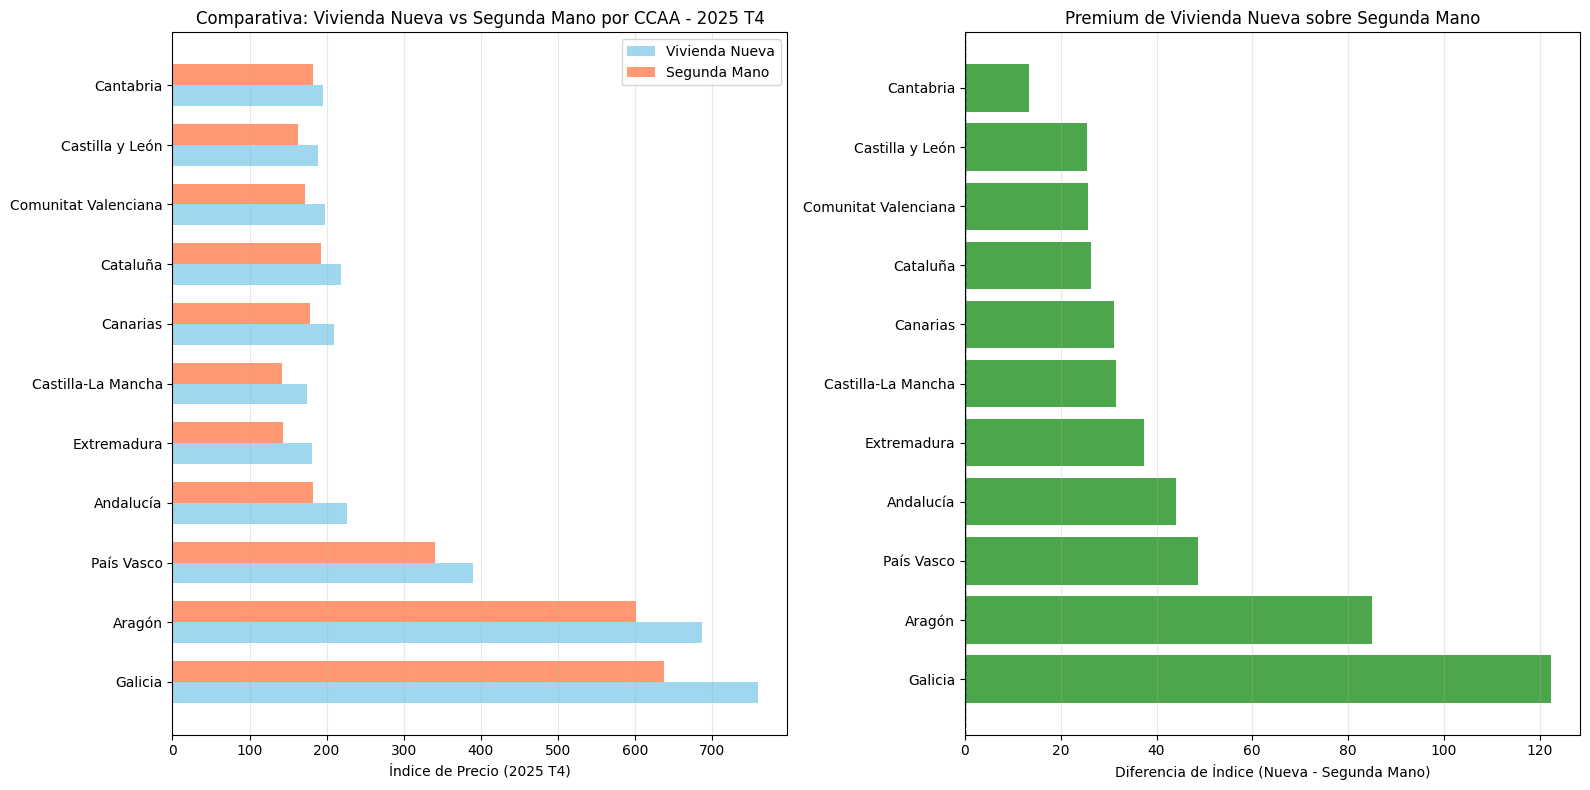

In [106]:
# Función mejorada para extraer la CCAA correctamente
def extract_ccaa_from_tipo(tipo_vivienda):
    # Formato: "vivienda_nueva_castilla_y_leon", "vivienda_segunda_mano_madrid", "general_nacional"
    # Tipos conocidos que debemos eliminar del inicio
    tipos_conocidos = ['vivienda_nueva', 'vivienda_segunda_mano', 'general', 'vivienda']
    
    # Intentar con cada tipo conocido
    for tipo in tipos_conocidos:
        if tipo_vivienda.startswith(tipo + '_'):
            # Extraer todo después del tipo
            ccaa = tipo_vivienda[len(tipo) + 1:]
            return ccaa
    
    # Si no empieza con ningún tipo conocido, devolver todo
    return tipo_vivienda

# Separar vivienda nueva y segunda mano - usar startswith para evitar duplicados
nueva = all_results[all_results['tipo_vivienda'].str.startswith('vivienda_nueva_')].copy()
segunda = all_results[
    all_results['tipo_vivienda'].str.startswith('vivienda_segunda_mano_') | 
    all_results['tipo_vivienda'].str.startswith('vivienda_de_segunda_mano_')
].copy()

print(f"Vivienda nueva encontrada: {len(nueva)} registros")
print(f"Vivienda segunda mano encontrada: {len(segunda)} registros")

if len(nueva) > 0 and len(segunda) > 0:
    nueva['ccaa'] = nueva['tipo_vivienda'].apply(extract_ccaa_from_tipo)
    segunda['ccaa'] = segunda['tipo_vivienda'].apply(extract_ccaa_from_tipo)

    # Agregar por CCAA y consolidar duplicados
    nueva_ccaa = nueva.groupby('ccaa', as_index=False).agg({
        'y_pred_2025T4': 'sum',
        'y_pred_2026T1': 'sum',
        'y_real_2025T3': 'sum'
    })
    segunda_ccaa = segunda.groupby('ccaa', as_index=False).agg({
        'y_pred_2025T4': 'sum',
        'y_pred_2026T1': 'sum',
        'y_real_2025T3': 'sum'
    })

    # Merge
    comparativa = nueva_ccaa.merge(segunda_ccaa, on='ccaa', suffixes=('_nueva', '_segunda'))
    
    if len(comparativa) > 0:
        comparativa['ccaa_nombre'] = comparativa['ccaa'].map(ccaa_pretty).fillna(comparativa['ccaa'].str.title())
        comparativa['diferencia'] = comparativa['y_pred_2025T4_nueva'] - comparativa['y_pred_2025T4_segunda']
        comparativa = comparativa[comparativa['ccaa'] != 'nacional'].sort_values('diferencia', ascending=False)

        if len(comparativa) > 0:
            # Visualización
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

            # Gráfico 1: Comparación lado a lado
            x = range(len(comparativa))
            width = 0.35

            ax1.barh([i - width/2 for i in x], comparativa['y_pred_2025T4_nueva'], 
                     width, label='Vivienda Nueva', color='skyblue', alpha=0.8)
            ax1.barh([i + width/2 for i in x], comparativa['y_pred_2025T4_segunda'], 
                     width, label='Segunda Mano', color='coral', alpha=0.8)

            ax1.set_yticks(x)
            ax1.set_yticklabels(comparativa['ccaa_nombre'])
            ax1.set_xlabel('Índice de Precio (2025 T4)')
            ax1.set_title('Comparativa: Vivienda Nueva vs Segunda Mano por CCAA - 2025 T4')
            ax1.legend()
            ax1.grid(axis='x', alpha=0.3)

            # Gráfico 2: Diferencia (premium vivienda nueva)
            colors = ['green' if d > 0 else 'red' for d in comparativa['diferencia']]
            ax2.barh(comparativa['ccaa_nombre'], comparativa['diferencia'], color=colors, alpha=0.7)
            ax2.axvline(0, color='black', linestyle='--', linewidth=1)
            ax2.set_xlabel('Diferencia de Índice (Nueva - Segunda Mano)')
            ax2.set_title('Premium de Vivienda Nueva sobre Segunda Mano')
            ax2.grid(axis='x', alpha=0.3)

            plt.tight_layout()
            # Calcular diferencias para 2026T1
            comparativa['diferencia_2026T1'] = comparativa['y_pred_2026T1_nueva'] - comparativa['y_pred_2026T1_segunda']
            
            # Tabla resumen
            print("\n" + "="*110)
            print("RESUMEN: DIFERENCIAL VIVIENDA NUEVA VS SEGUNDA MANO (2025 T4 y 2026 T1)")
            print("="*110)
            print(f"{'CCAA':25s} {'Nueva T4':>10s} {'Segunda T4':>10s} {'Dif T4':>10s} {'Nueva T1':>10s} {'Segunda T1':>10s} {'Dif T1':>10s}")
            print("-"*110)
            for _, row in comparativa.iterrows():
                print(f"{row['ccaa_nombre']:25s} "
                      f"{row['y_pred_2025T4_nueva']:>10.2f} {row['y_pred_2025T4_segunda']:>10.2f} {row['diferencia']:>10.2f} "
                      f"{row['y_pred_2026T1_nueva']:>10.2f} {row['y_pred_2026T1_segunda']:>10.2f} {row['diferencia_2026T1']:>10.2f}")
            print("="*110)
        else:
            print("⚠️ No hay datos después de filtrar 'nacional'")
    else:

        print("⚠️ El merge no produjo resultados")
else:    print("⚠️ No se encontraron datos de vivienda nueva o segunda mano")



**5. Tasa de Crecimiento Acumulada (Últimos 5 años)**

Total de periodos disponibles: 75

Calculando crecimiento de 2007T1 a 2025T3
Periodo analizado: ~18.8 años (75 trimestres)


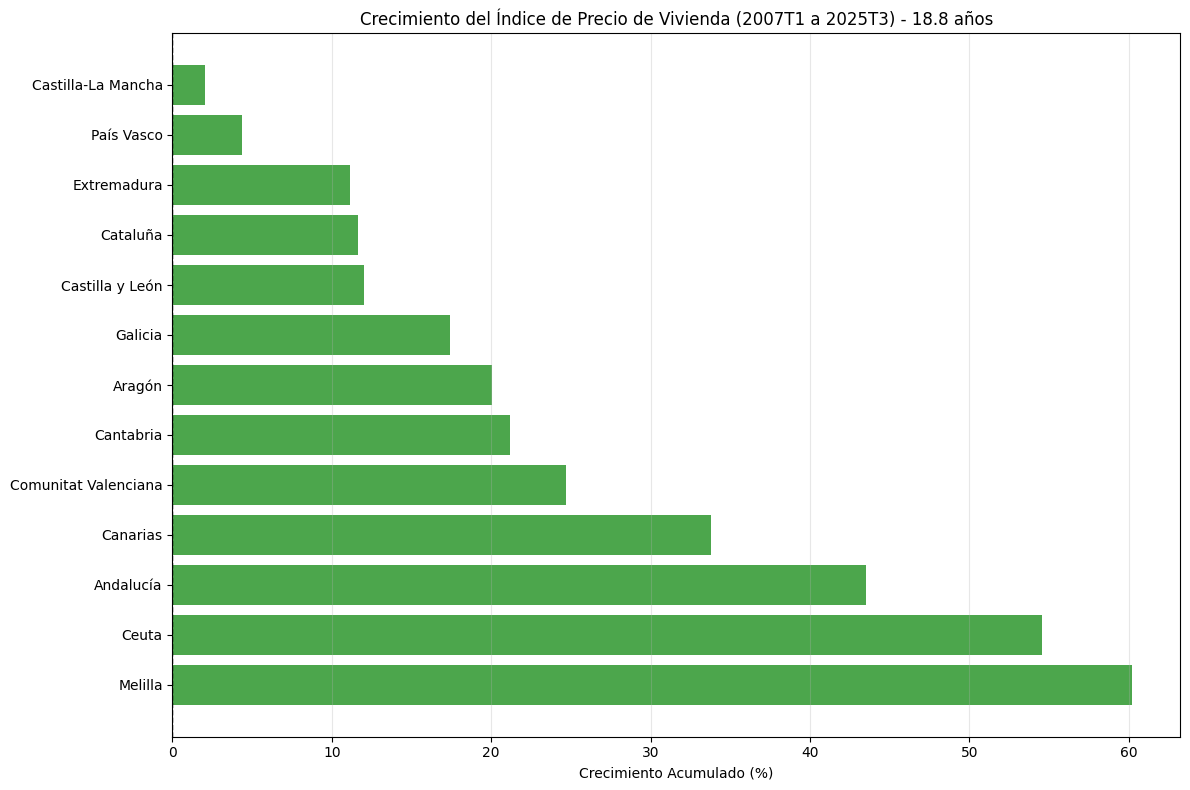


CRECIMIENTO ACUMULADO DEL ÍNDICE DE PRECIO DE VIVIENDA (18.8 AÑOS)

Top 5 CCAA con mayor crecimiento:
  Melilla                  :   124.88 →   200.06 ( +60.21%)
  Ceuta                    :   132.36 →   204.60 ( +54.58%)
  Andalucía                :   127.08 →   182.37 ( +43.51%)
  Canarias                 :   132.56 →   177.38 ( +33.81%)
  Comunitat Valenciana     :   137.10 →   170.96 ( +24.69%)

Top 5 CCAA con menor crecimiento:
  Castilla y León          :   144.62 →   162.04 ( +12.04%)
  Cataluña                 :   170.69 →   190.56 ( +11.64%)
  Extremadura              :   128.93 →   143.25 ( +11.11%)
  País Vasco               :   323.06 →   337.25 (  +4.39%)
  Castilla-La Mancha       :   142.16 →   145.06 (  +2.04%)

Crecimiento promedio:  +24.36%
Total de CCAA analizadas: 13


In [107]:
# Función para extraer CCAA (igual que en KPI 4)
def extract_ccaa_from_tipo(tipo_vivienda):
    tipos_conocidos = ['vivienda_nueva', 'vivienda_segunda_mano', 'general', 'vivienda']
    for tipo in tipos_conocidos:
        if tipo_vivienda.startswith(tipo + '_'):
            return tipo_vivienda[len(tipo) + 1:]
    return tipo_vivienda

# Verificar cuántos periodos tenemos
num_periodos = len(period_cols)
print(f"Total de periodos disponibles: {num_periodos}")

# Usar todos los periodos disponibles
if num_periodos >= 8:  # Al menos 2 años de datos
    periodo_inicial = period_cols[0]    # Primer periodo disponible
    periodo_final = period_cols[-1]     # Último disponible
    
    # Calcular años aproximados
    años_aprox = num_periodos / 4
    
    print(f"\nCalculando crecimiento de {periodo_inicial} a {periodo_final}")
    print(f"Periodo analizado: ~{años_aprox:.1f} años ({num_periodos} trimestres)")
    
    df_crecimiento = df_kpi.copy()
    df_crecimiento['precio_inicial'] = df_crecimiento[periodo_inicial]
    df_crecimiento['precio_final'] = df_crecimiento[periodo_final]
    
    # Extraer CCAA antes de filtrar
    df_crecimiento['ccaa'] = df_crecimiento['tipo_vivienda'].apply(extract_ccaa_from_tipo)
    df_crecimiento['ccaa_nombre'] = df_crecimiento['ccaa'].map(ccaa_pretty).fillna(df_crecimiento['ccaa'].str.title())
    
    # Solo vivienda general por CCAA (excluir nueva y segunda mano)
    df_general = df_crecimiento[
        df_crecimiento['tipo_vivienda'].str.startswith('general_')
    ].copy()
    
    # Agrupar por CCAA para consolidar posibles duplicados
    df_general = df_general.groupby(['ccaa', 'ccaa_nombre'], as_index=False).agg({
        'precio_inicial': 'sum',
        'precio_final': 'sum'
    })
    
    # Eliminar filas con valores NaN o cero en precio inicial (para evitar divisiones problemáticas)
    df_general = df_general[
        (df_general['precio_inicial'].notna()) & 
        (df_general['precio_final'].notna()) &
        (df_general['precio_inicial'] > 1)  # Filtrar valores muy bajos que causan porcentajes irreales
    ].copy()
    
    # Calcular crecimiento después de filtrar
    df_general['crecimiento_pct'] = (
        (df_general['precio_final'] - df_general['precio_inicial']) / 
        df_general['precio_inicial'] * 100
    )
    
    if len(df_general) > 0:
        df_general_sorted = df_general[df_general['ccaa'] != 'nacional'].sort_values(
            'crecimiento_pct', ascending=False
        )
        
        if len(df_general_sorted) > 0:
            # Visualización
            plt.figure(figsize=(12, 8))
            colors = ['green' if x > 0 else 'red' for x in df_general_sorted['crecimiento_pct']]
            plt.barh(df_general_sorted['ccaa_nombre'], df_general_sorted['crecimiento_pct'], 
                     color=colors, alpha=0.7)
            plt.axvline(0, color='black', linestyle='--', linewidth=1)
            plt.xlabel('Crecimiento Acumulado (%)')
            plt.title(f'Crecimiento del Índice de Precio de Vivienda ({periodo_inicial} a {periodo_final}) - {años_aprox:.1f} años')
            plt.grid(axis='x', alpha=0.3)
            plt.tight_layout()
            plt.show()
            
            # Estadísticas
            print("\n" + "="*80)
            print(f"CRECIMIENTO ACUMULADO DEL ÍNDICE DE PRECIO DE VIVIENDA ({años_aprox:.1f} AÑOS)")
            print("="*80)
            
            num_registros = len(df_general_sorted)
            top_n = min(5, num_registros)
            
            print(f"\nTop {top_n} CCAA con mayor crecimiento:")
            for _, row in df_general_sorted.head(top_n).iterrows():
                print(f"  {row['ccaa_nombre']:25s}: {row['precio_inicial']:>8.2f} → {row['precio_final']:>8.2f} "
                      f"({row['crecimiento_pct']:>+7.2f}%)")
            
            if num_registros > 5:
                print(f"\nTop 5 CCAA con menor crecimiento:")
                for _, row in df_general_sorted.tail(5).iterrows():
                    print(f"  {row['ccaa_nombre']:25s}: {row['precio_inicial']:>8.2f} → {row['precio_final']:>8.2f} "
                          f"({row['crecimiento_pct']:>+7.2f}%)")
            
            print(f"\nCrecimiento promedio: {df_general_sorted['crecimiento_pct'].mean():>+7.2f}%")
            print(f"Total de CCAA analizadas: {num_registros}")
            print("="*80)
        else:
            print("⚠️ No hay datos después de filtrar 'nacional'")
    else:
        print("⚠️ No se encontraron registros válidos de vivienda general")
else:
    print(f"\n⚠️ No hay suficientes datos históricos para el análisis")
    print(f"Se necesitan al menos 8 trimestres pero solo hay {num_periodos} disponibles")

**6. Volatilidad del Precio por CCAA**

Registros de vivienda general encontrados: 14
Registros después de filtrar nacional: 13


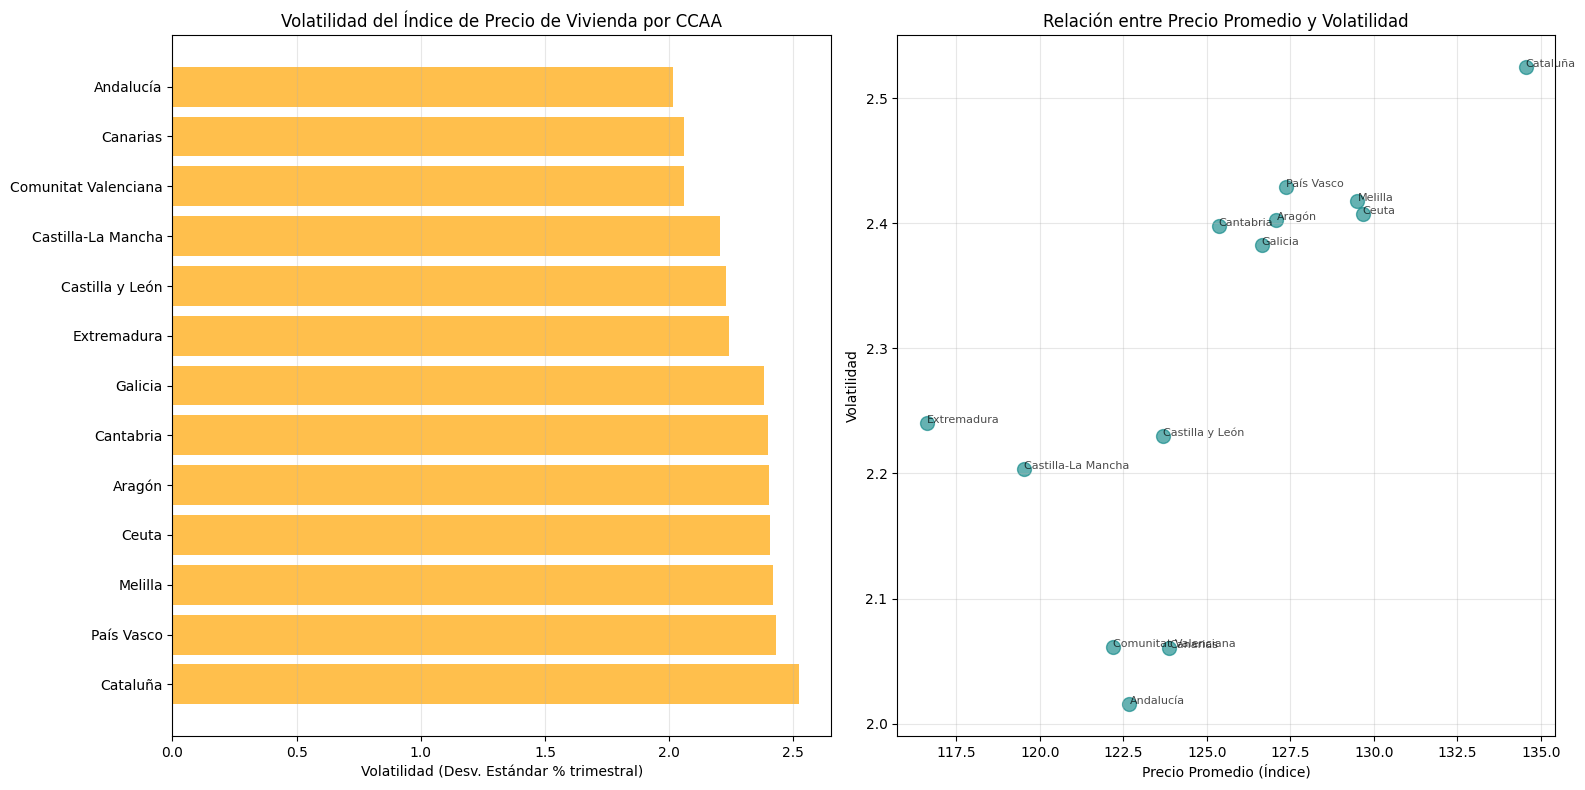


VOLATILIDAD DEL MERCADO DE VIVIENDA POR CCAA
CCAA                       Precio Promedio  Volatilidad
--------------------------------------------------------------------------------
Cataluña                            134.54         2.53%
País Vasco                          127.36         2.43%
Melilla                             129.51         2.42%
Ceuta                               129.67         2.41%
Aragón                              127.09         2.40%
Cantabria                           125.36         2.40%
Galicia                             126.65         2.38%
Extremadura                         116.63         2.24%
Castilla y León                     123.69         2.23%
Castilla-La Mancha                  119.53         2.20%
Comunitat Valenciana                122.19         2.06%
Canarias                            123.88         2.06%
Andalucía                           122.69         2.02%

Volatilidad promedio:                              2.29%
CCAA más volátil: 

In [108]:
# Función para extraer CCAA (igual que en KPI 4 y 5)
def extract_ccaa_from_tipo(tipo_vivienda):
    tipos_conocidos = ['vivienda_nueva', 'vivienda_segunda_mano', 'general', 'vivienda']
    for tipo in tipos_conocidos:
        if tipo_vivienda.startswith(tipo + '_'):
            return tipo_vivienda[len(tipo) + 1:]
    return tipo_vivienda

# Calcular volatilidad (desviación estándar de cambios trimestrales)
df_volatilidad = df_kpi.copy()

# Calcular cambios trimestrales porcentuales
cambios = df_kpi[period_cols].pct_change(axis=1) * 100

# Calcular desviación estándar de los cambios (volatilidad)
df_volatilidad['volatilidad'] = cambios.std(axis=1)
df_volatilidad['precio_promedio'] = df_kpi[period_cols].mean(axis=1)

# Extraer CCAA
df_volatilidad['ccaa'] = df_volatilidad['tipo_vivienda'].apply(extract_ccaa_from_tipo)
df_volatilidad['ccaa_nombre'] = df_volatilidad['ccaa'].map(ccaa_pretty).fillna(df_volatilidad['ccaa'].str.title())

# Filtrar solo vivienda general (usar general_ en lugar de vivienda_)
df_vol_general = df_volatilidad[
    df_volatilidad['tipo_vivienda'].str.startswith('general_')
].copy()

# Agrupar por CCAA para consolidar posibles duplicados
df_vol_general = df_vol_general.groupby(['ccaa', 'ccaa_nombre'], as_index=False).agg({
    'volatilidad': 'mean',
    'precio_promedio': 'mean'
})

print(f"Registros de vivienda general encontrados: {len(df_vol_general)}")

if len(df_vol_general) > 0:
    df_vol_sorted = df_vol_general[df_vol_general['ccaa'] != 'nacional'].sort_values(
        'volatilidad', ascending=False
    )
    
    print(f"Registros después de filtrar nacional: {len(df_vol_sorted)}")
    
    if len(df_vol_sorted) > 0:
        # Visualización 1: Volatilidad por CCAA
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

        ax1.barh(df_vol_sorted['ccaa_nombre'], df_vol_sorted['volatilidad'], 
                 color='orange', alpha=0.7)
        ax1.set_xlabel('Volatilidad (Desv. Estándar % trimestral)')
        ax1.set_title('Volatilidad del Índice de Precio de Vivienda por CCAA')
        ax1.grid(axis='x', alpha=0.3)

        # Visualización 2: Scatter - Precio vs Volatilidad
        ax2.scatter(df_vol_sorted['precio_promedio'], df_vol_sorted['volatilidad'], 
                   s=100, alpha=0.6, color='teal')

        for _, row in df_vol_sorted.iterrows():
            ax2.annotate(row['ccaa_nombre'], 
                        (row['precio_promedio'], row['volatilidad']),
                        fontsize=8, alpha=0.7)

        ax2.set_xlabel('Precio Promedio (Índice)')
        ax2.set_ylabel('Volatilidad')
        ax2.set_title('Relación entre Precio Promedio y Volatilidad')
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

        # Resumen
        print("\n" + "="*80)
        print("VOLATILIDAD DEL MERCADO DE VIVIENDA POR CCAA")
        print("="*80)
        print(f"{'CCAA':25s} {'Precio Promedio':>16s} {'Volatilidad':>12s}")
        print("-"*80)
        for _, row in df_vol_sorted.iterrows():
            print(f"{row['ccaa_nombre']:25s} {row['precio_promedio']:>16.2f} {row['volatilidad']:>12.2f}%")

        print(f"\n{'Volatilidad promedio:':25s} {df_vol_sorted['volatilidad'].mean():>29.2f}%")
        print(f"{'CCAA más volátil:':25s} {df_vol_sorted.iloc[0]['ccaa_nombre']:>29s}")
        print(f"{'CCAA más estable:':25s} {df_vol_sorted.iloc[-1]['ccaa_nombre']:>29s}")
        print("="*80)
    else:
        print("⚠️ No hay datos después de filtrar 'nacional'")
else:
    print("⚠️ No se encontraron registros de vivienda general")

**7. Dashboard Resumen: Predicción 2025 T4 vs Situación Actual**

Registros de vivienda general encontrados: 20
Registros después de filtrar nacional y agrupar: 13


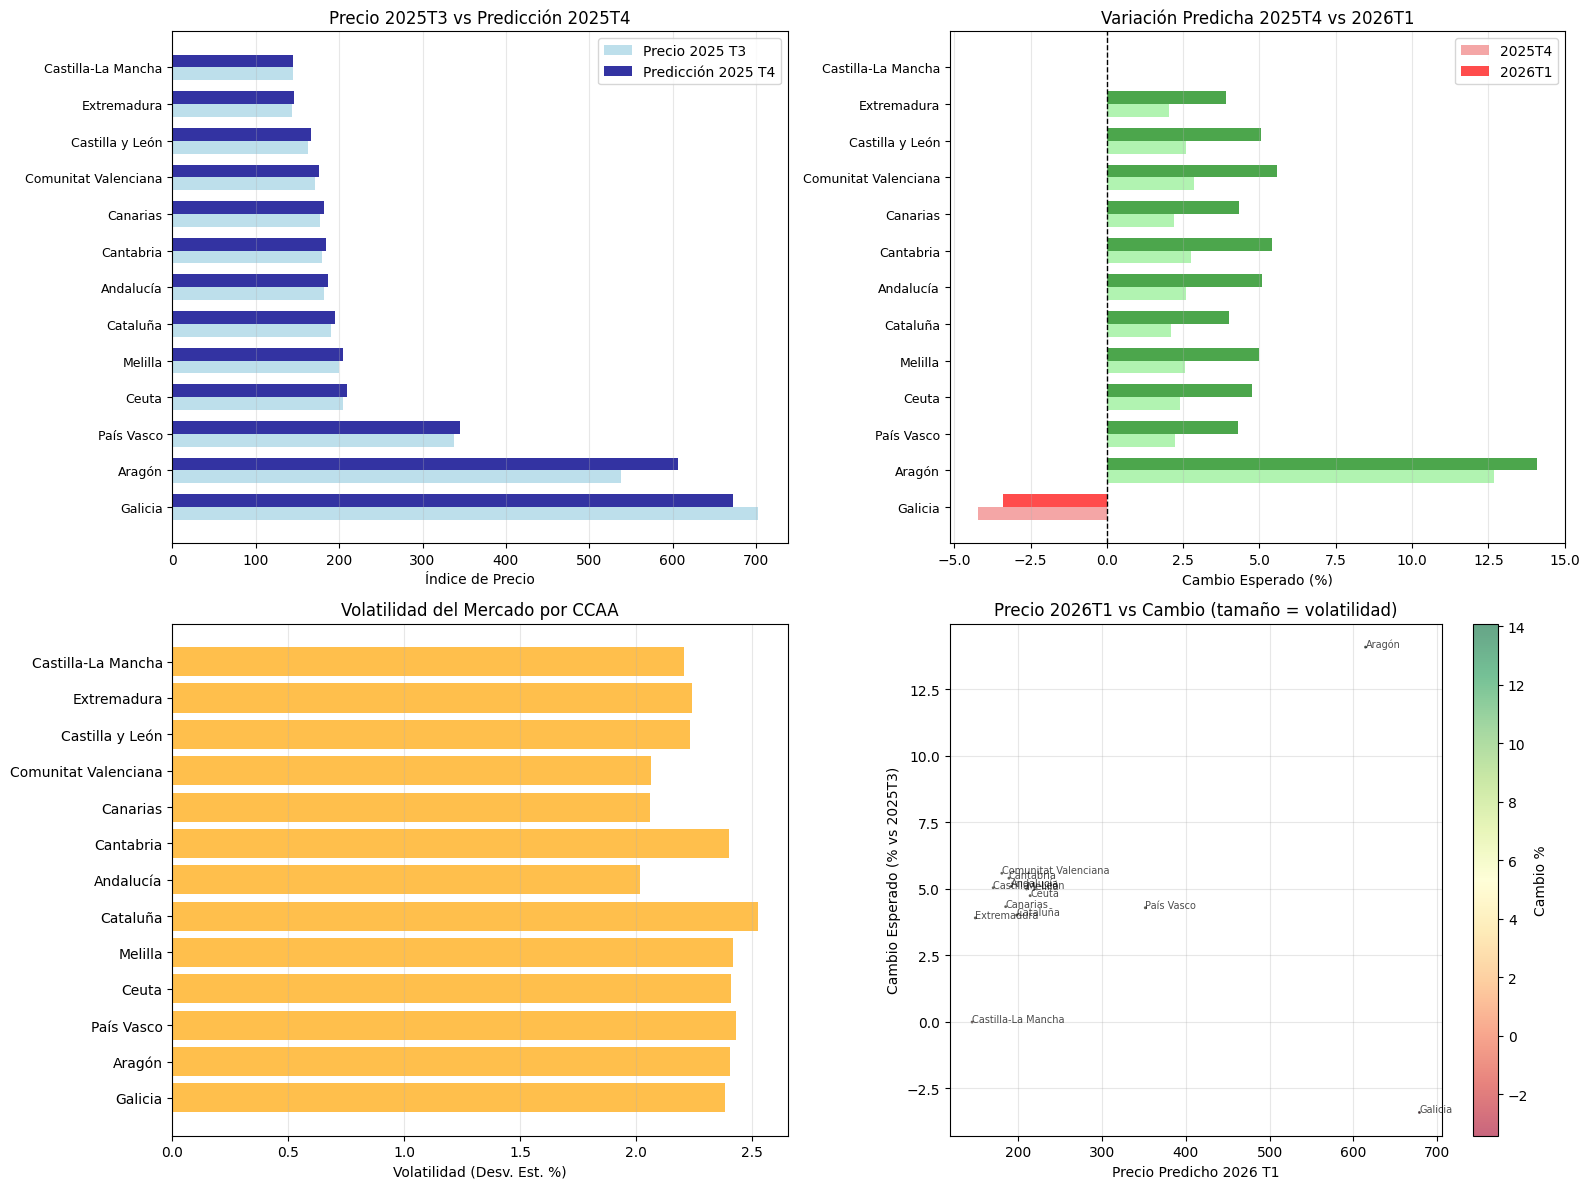


DASHBOARD RESUMEN - ÍNDICE DE PRECIO DE VIVIENDA POR CCAA (2025T3 → 2026T1)
CCAA                         2025 T3     2025T4    Δ T4%     2026T1    Δ T1%  Volatilidad
----------------------------------------------------------------------------------------------------------------------------------
Galicia                       702.70     672.95   -4.23%     678.73   -3.41%        2.38%
Aragón                        538.57     606.86   12.68%     614.45   14.09%        2.40%
País Vasco                    337.25     344.75    2.22%     351.71    4.29%        2.43%
Ceuta                         204.60     209.51    2.40%     214.30    4.74%        2.41%
Melilla                       200.06     205.15    2.55%     210.05    4.99%        2.42%
Cataluña                      190.56     194.55    2.09%     198.21    4.01%        2.53%
Andalucía                     182.37     187.11    2.60%     191.65    5.09%        2.02%
Cantabria                     179.33     184.27    2.75%     189.01    5

In [109]:
# Función para extraer CCAA (igual que en KPI 4, 5 y 6)
def extract_ccaa_from_tipo(tipo_vivienda):
    tipos_conocidos = ['vivienda_nueva', 'vivienda_segunda_mano', 'general', 'vivienda']
    for tipo in tipos_conocidos:
        if tipo_vivienda.startswith(tipo + '_'):
            return tipo_vivienda[len(tipo) + 1:]
    return tipo_vivienda

# Crear dashboard consolidado
dashboard = all_results.copy()
dashboard['ccaa'] = dashboard['tipo_vivienda'].apply(extract_ccaa_from_tipo)
dashboard['tipo'] = dashboard['tipo_vivienda'].apply(lambda x: x.split('_')[0])

# Filtrar solo vivienda general por CCAA (excluir nacional)
dashboard_general = dashboard[
    dashboard['tipo_vivienda'].str.startswith('general_')
].copy()

print(f"Registros de vivienda general encontrados: {len(dashboard_general)}")

dashboard_general = dashboard_general[dashboard_general['ccaa'] != 'nacional'].copy()

# Agrupar por CCAA para consolidar posibles duplicados
dashboard_general = dashboard_general.groupby('ccaa', as_index=False).agg({
    'y_real_2025T3': 'sum',
    'y_pred_2025T4': 'sum',
    'y_pred_2026T1': 'sum'
})

# Añadir nombres bonitos después de agrupar
dashboard_general['ccaa_nombre'] = dashboard_general['ccaa'].map(ccaa_pretty).fillna(dashboard_general['ccaa'].str.title())

print(f"Registros después de filtrar nacional y agrupar: {len(dashboard_general)}")

if len(dashboard_general) > 0:
    dashboard_general['cambio_absoluto_T4'] = dashboard_general['y_pred_2025T4'] - dashboard_general['y_real_2025T3']
    dashboard_general['cambio_pct_T4'] = (dashboard_general['cambio_absoluto_T4'] / dashboard_general['y_real_2025T3'] * 100)
    dashboard_general['cambio_absoluto_T1'] = dashboard_general['y_pred_2026T1'] - dashboard_general['y_real_2025T3']
    dashboard_general['cambio_pct_T1'] = (dashboard_general['cambio_absoluto_T1'] / dashboard_general['y_real_2025T3'] * 100)

    # Merge con volatilidad
    dashboard_final = dashboard_general.merge(
        df_vol_general[['ccaa', 'volatilidad']],
        on='ccaa',
        how='left'
    )

    # Ordenar por precio predicho 2026T1
    dashboard_final = dashboard_final.sort_values('y_pred_2026T1', ascending=False)

    # Visualización: Dashboard con 4 gráficos
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Gráfico 1: Precio actual vs predicho
    ax = axes[0, 0]
    x = range(len(dashboard_final))
    width = 0.35
    ax.barh([i - width/2 for i in x], dashboard_final['y_real_2025T3'], 
            width, label='Precio 2025 T3', color='lightblue', alpha=0.8)
    ax.barh([i + width/2 for i in x], dashboard_final['y_pred_2025T4'], 
            width, label='Predicción 2025 T4', color='darkblue', alpha=0.8)
    ax.set_yticks(x)
    ax.set_yticklabels(dashboard_final['ccaa_nombre'], fontsize=9)
    ax.set_xlabel('Índice de Precio')
    ax.set_title('Precio 2025T3 vs Predicción 2025T4')
    ax.legend()
    ax.grid(axis='x', alpha=0.3)

    # Gráfico 2: Cambio esperado (%) - comparar T4 vs T1
    ax = axes[0, 1]
    x_pos = range(len(dashboard_final))
    width = 0.35
    
    colors_t4 = ['lightgreen' if x > 0 else 'lightcoral' for x in dashboard_final['cambio_pct_T4']]
    colors_t1 = ['green' if x > 0 else 'red' for x in dashboard_final['cambio_pct_T1']]
    
    ax.barh([i - width/2 for i in x_pos], dashboard_final['cambio_pct_T4'], 
            width, label='2025T4', color=colors_t4, alpha=0.7)
    ax.barh([i + width/2 for i in x_pos], dashboard_final['cambio_pct_T1'], 
            width, label='2026T1', color=colors_t1, alpha=0.7)
    
    ax.set_yticks(x_pos)
    ax.set_yticklabels(dashboard_final['ccaa_nombre'], fontsize=9)
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    ax.set_xlabel('Cambio Esperado (%)')
    ax.set_title('Variación Predicha 2025T4 vs 2026T1')
    ax.legend()
    ax.grid(axis='x', alpha=0.3)

    # Gráfico 3: Volatilidad
    ax = axes[1, 0]
    ax.barh(dashboard_final['ccaa_nombre'], dashboard_final['volatilidad'], 
            color='orange', alpha=0.7)
    ax.set_xlabel('Volatilidad (Desv. Est. %)')
    ax.set_title('Volatilidad del Mercado por CCAA')
    ax.grid(axis='x', alpha=0.3)

    # Gráfico 4: Scatter (Precio 2026T1 vs Cambio vs Volatilidad)
    ax = axes[1, 1]
    scatter = ax.scatter(dashboard_final['y_pred_2026T1'], 
                         dashboard_final['cambio_pct_T1'],
                         s=dashboard_final['volatilidad']*0.5,
                         c=dashboard_final['cambio_pct_T1'],
                         cmap='RdYlGn',
                         alpha=0.6,
                         edgecolors='black')

    for _, row in dashboard_final.iterrows():
        ax.annotate(row['ccaa_nombre'], 
                    (row['y_pred_2026T1'], row['cambio_pct_T1']),
                    fontsize=7, alpha=0.7)

    ax.set_xlabel('Precio Predicho 2026 T1')
    ax.set_ylabel('Cambio Esperado (% vs 2025T3)')
    ax.set_title('Precio 2026T1 vs Cambio (tamaño = volatilidad)')
    ax.grid(True, alpha=0.3)
    plt.colorbar(scatter, ax=ax, label='Cambio %')

    plt.tight_layout()
    plt.show()

    # Tabla resumen
    print("\n" + "="*130)
    print("DASHBOARD RESUMEN - ÍNDICE DE PRECIO DE VIVIENDA POR CCAA (2025T3 → 2026T1)")
    print("="*130)
    print(f"{'CCAA':25s} {'2025 T3':>10s} {'2025T4':>10s} {'Δ T4%':>8s} {'2026T1':>10s} {'Δ T1%':>8s} {'Volatilidad':>12s}")
    print("-"*130)

    for _, row in dashboard_final.iterrows():
        print(f"{row['ccaa_nombre']:25s} "
              f"{row['y_real_2025T3']:>10.2f} "
              f"{row['y_pred_2025T4']:>10.2f} "
              f"{row['cambio_pct_T4']:>7.2f}% "
              f"{row['y_pred_2026T1']:>10.2f} "
              f"{row['cambio_pct_T1']:>7.2f}% "
              f"{row['volatilidad']:>11.2f}%")

    print("="*130)
    print(f"\n{'Estadísticas Generales:':25s}")
    print(f"  Precio promedio 2025 T3:       {dashboard_final['y_real_2025T3'].mean():>10.2f}")
    print(f"  Precio promedio 2025T4:        {dashboard_final['y_pred_2025T4'].mean():>10.2f}")
    print(f"  Precio promedio 2026T1:        {dashboard_final['y_pred_2026T1'].mean():>10.2f}")
    print(f"  Cambio promedio T4:            {dashboard_final['cambio_pct_T4'].mean():>9.2f}%")
    print(f"  Cambio promedio T1:            {dashboard_final['cambio_pct_T1'].mean():>9.2f}%")
    print(f"  Volatilidad promedio:          {dashboard_final['volatilidad'].mean():>10.2f}%")
    print(f"\n  CCAA más cara (2026T1):        {dashboard_final.iloc[0]['ccaa_nombre']}")
    print(f"  CCAA más barata (2026T1):      {dashboard_final.iloc[-1]['ccaa_nombre']}")
    print(f"  Mayor crecimiento T1:          {dashboard_final.loc[dashboard_final['cambio_pct_T1'].idxmax(), 'ccaa_nombre']}")
    print(f"  Mayor volatilidad:             {dashboard_final.loc[dashboard_final['volatilidad'].idxmax(), 'ccaa_nombre']}")
    print("="*130)
else:
    print("⚠️ No se encontraron registros de vivienda general")


📊 ANÁLISIS VISUAL DE ESTADÍSTICAS DE VIVIENDA POR CCAA

📋 Datos cargados:
    Comunidad Autonoma  variación porcentual del precio por ccaa  \
0                 CCAA                              Var_Pred_Pct   
1                Ceuta                         9.187392950740243   
2              Melilla                         8.955189689856452   
3               Madrid                          8.85274458183419   
4            Andalucía                         7.507289555198264   
5             Canarias                         7.504278427940458   
6             Nacional                         7.491663332928268   
7               Murcia                         6.494430835147526   
8             Valencia                         6.347572912800495   
9              Galicia                         6.291223186351526   
10            Asturias                        6.0923280608194395   
11             Balears                         5.983938555797716   
12     Castilla y León                    

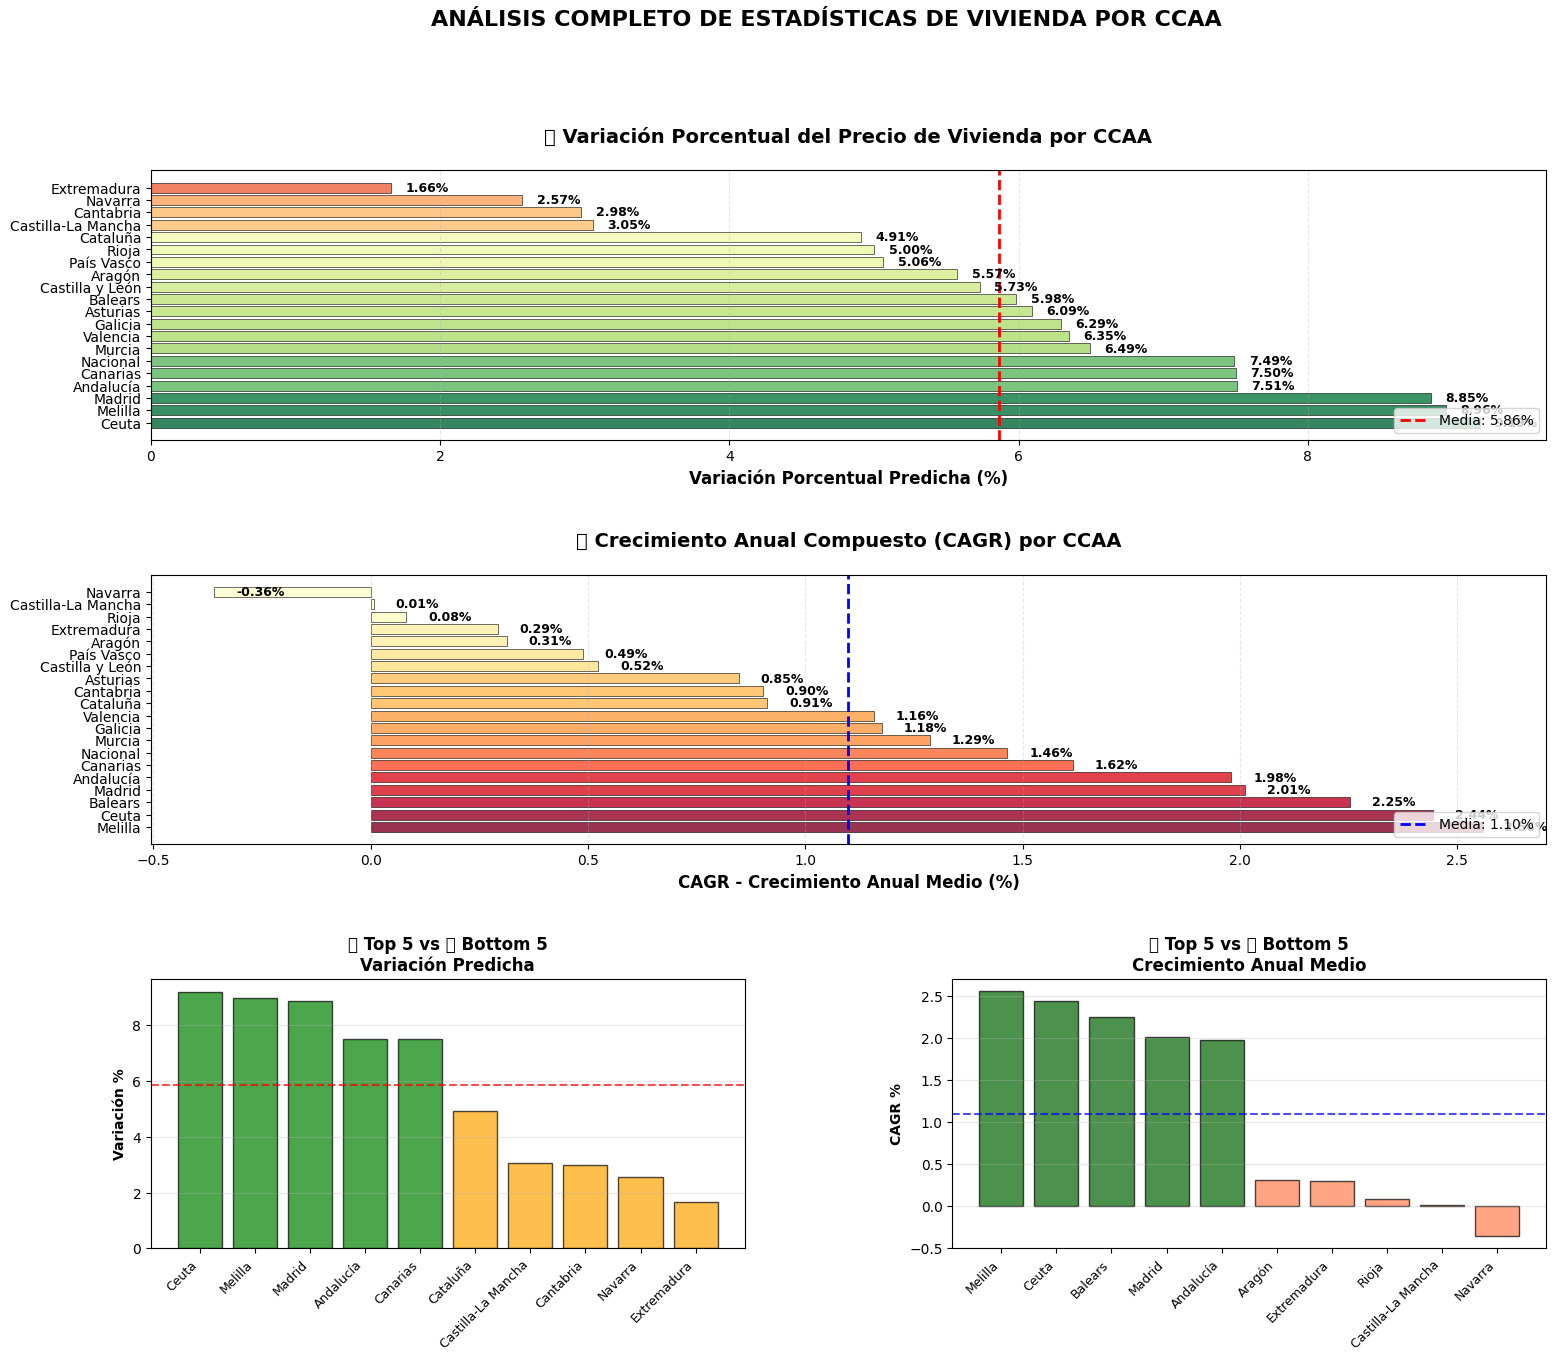


📊 ANÁLISIS DE CORRELACIÓN: VARIACIÓN PREDICHA VS CRECIMIENTO ANUAL MEDIO


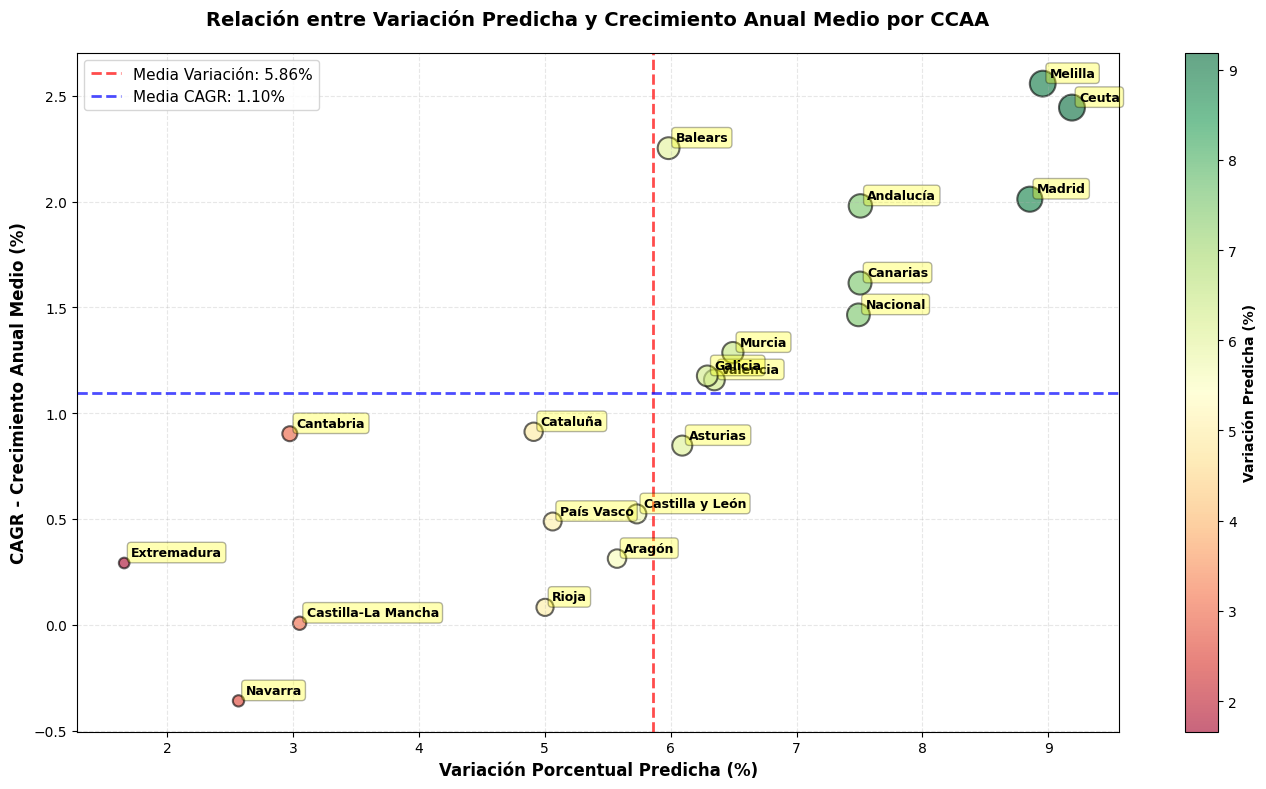


📋 TABLA RESUMEN DE ESTADÍSTICAS POR CCAA

  Rank Var   Rank CAGR CCAA                          Variación %       CAGR %       Tendencia
----------------------------------------------------------------------------------------------------
         1           2 Ceuta                                9.19         2.44      🔥 MUY ALTA
         2           1 Melilla                              8.96         2.56      🔥 MUY ALTA
         3           4 Madrid                               8.85         2.01      🔥 MUY ALTA
         4           5 Andalucía                            7.51         1.98          🔼 ALTA
         5           6 Canarias                             7.50         1.62          🔼 ALTA
         6           7 Nacional                             7.49         1.46          🔼 ALTA
         7           8 Murcia                               6.49         1.29          🔼 ALTA
         8          10 Valencia                             6.35         1.16          🔼 ALTA
         9

In [110]:
# Leer archivo de estadísticas de vivienda (CSV)
df_stats = pd.read_csv('estadisticas_vivienda.csv')

print("="*100)
print("📊 ANÁLISIS VISUAL DE ESTADÍSTICAS DE VIVIENDA POR CCAA")
print("="*100)

# Mostrar datos
print("\n📋 Datos cargados:")
print(df_stats)
print(f"\nColumnas: {df_stats.columns.tolist()}")
print(f"Total de CCAA analizadas: {len(df_stats)}")

# Renombrar columnas para facilitar el trabajo
df_stats.columns = ['ccaa', 'variacion_pred_pct', 'cagr_pct']

# Convertir columnas numéricas a float
df_stats['variacion_pred_pct'] = pd.to_numeric(df_stats['variacion_pred_pct'], errors='coerce')
df_stats['cagr_pct'] = pd.to_numeric(df_stats['cagr_pct'], errors='coerce')

# Eliminar filas con valores NaN
df_stats = df_stats.dropna()

# Ordenar datos para mejor visualización
df_stats_sorted_var = df_stats.sort_values('variacion_pred_pct', ascending=False)
df_stats_sorted_cagr = df_stats.sort_values('cagr_pct', ascending=False)

# ========== VISUALIZACIÓN 1: DASHBOARD COMPLETO ==========
print("\n" + "="*100)
print("📊 DASHBOARD COMPLETO DE ESTADÍSTICAS")
print("="*100)

fig = plt.figure(figsize=(18, 14))
gs = fig.add_gridspec(3, 2, hspace=0.5, wspace=0.35)

# Gráfico 1: Variación Porcentual Predicha (Barras horizontales)
ax1 = fig.add_subplot(gs[0, :])
colors_var = plt.cm.RdYlGn(df_stats_sorted_var['variacion_pred_pct'] / df_stats_sorted_var['variacion_pred_pct'].max())
bars1 = ax1.barh(df_stats_sorted_var['ccaa'], df_stats_sorted_var['variacion_pred_pct'], 
                 color=colors_var, alpha=0.8, edgecolor='black', linewidth=0.5)
ax1.set_xlabel('Variación Porcentual Predicha (%)', fontsize=12, fontweight='bold')
ax1.set_title('📈 Variación Porcentual del Precio de Vivienda por CCAA', 
              fontsize=14, fontweight='bold', pad=20)
ax1.grid(axis='x', alpha=0.3, linestyle='--')
ax1.axvline(df_stats['variacion_pred_pct'].mean(), color='red', linestyle='--', 
            linewidth=2, label=f'Media: {df_stats["variacion_pred_pct"].mean():.2f}%')

# Agregar valores en las barras
for i, (idx, row) in enumerate(df_stats_sorted_var.iterrows()):
    ax1.text(row['variacion_pred_pct'] + 0.1, i, f"{row['variacion_pred_pct']:.2f}%", 
             va='center', fontsize=9, fontweight='bold')

ax1.legend(loc='lower right', fontsize=10)

# Gráfico 2: CAGR (Crecimiento Anual Medio) - Barras horizontales
ax2 = fig.add_subplot(gs[1, :])
colors_cagr = plt.cm.YlOrRd(df_stats_sorted_cagr['cagr_pct'] / df_stats_sorted_cagr['cagr_pct'].max())
bars2 = ax2.barh(df_stats_sorted_cagr['ccaa'], df_stats_sorted_cagr['cagr_pct'], 
                 color=colors_cagr, alpha=0.8, edgecolor='black', linewidth=0.5)
ax2.set_xlabel('CAGR - Crecimiento Anual Medio (%)', fontsize=12, fontweight='bold')
ax2.set_title('📊 Crecimiento Anual Compuesto (CAGR) por CCAA', 
              fontsize=14, fontweight='bold', pad=20)
ax2.grid(axis='x', alpha=0.3, linestyle='--')
ax2.axvline(df_stats['cagr_pct'].mean(), color='blue', linestyle='--', 
            linewidth=2, label=f'Media: {df_stats["cagr_pct"].mean():.2f}%')

# Agregar valores en las barras
for i, (idx, row) in enumerate(df_stats_sorted_cagr.iterrows()):
    ax2.text(row['cagr_pct'] + 0.05, i, f"{row['cagr_pct']:.2f}%", 
             va='center', fontsize=9, fontweight='bold')

ax2.legend(loc='lower right', fontsize=10)

# Gráfico 3: Comparación Top 5 vs Bottom 5 - Variación
ax3 = fig.add_subplot(gs[2, 0])
top5_var = df_stats_sorted_var.head(5)
bottom5_var = df_stats_sorted_var.tail(5)
combined_var = pd.concat([top5_var, bottom5_var])

colors_comparison = ['green' if x > df_stats['variacion_pred_pct'].mean() else 'orange' 
                     for x in combined_var['variacion_pred_pct']]

ax3.bar(range(len(combined_var)), combined_var['variacion_pred_pct'], 
        color=colors_comparison, alpha=0.7, edgecolor='black', linewidth=1)
ax3.set_xticks(range(len(combined_var)))
ax3.set_xticklabels(combined_var['ccaa'], rotation=45, ha='right', fontsize=9)
ax3.set_ylabel('Variación %', fontsize=10, fontweight='bold')
ax3.set_title('🔝 Top 5 vs 🔻 Bottom 5\nVariación Predicha', fontsize=12, fontweight='bold')
ax3.axhline(df_stats['variacion_pred_pct'].mean(), color='red', linestyle='--', linewidth=1.5, alpha=0.7)
ax3.grid(axis='y', alpha=0.3)

# Gráfico 4: Comparación Top 5 vs Bottom 5 - CAGR
ax4 = fig.add_subplot(gs[2, 1])
top5_cagr = df_stats_sorted_cagr.head(5)
bottom5_cagr = df_stats_sorted_cagr.tail(5)
combined_cagr = pd.concat([top5_cagr, bottom5_cagr])

colors_comparison2 = ['darkgreen' if x > df_stats['cagr_pct'].mean() else 'coral' 
                      for x in combined_cagr['cagr_pct']]

ax4.bar(range(len(combined_cagr)), combined_cagr['cagr_pct'], 
        color=colors_comparison2, alpha=0.7, edgecolor='black', linewidth=1)
ax4.set_xticks(range(len(combined_cagr)))
ax4.set_xticklabels(combined_cagr['ccaa'], rotation=45, ha='right', fontsize=9)
ax4.set_ylabel('CAGR %', fontsize=10, fontweight='bold')
ax4.set_title('🔝 Top 5 vs 🔻 Bottom 5\nCrecimiento Anual Medio', fontsize=12, fontweight='bold')
ax4.axhline(df_stats['cagr_pct'].mean(), color='blue', linestyle='--', linewidth=1.5, alpha=0.7)
ax4.grid(axis='y', alpha=0.3)

plt.suptitle('ANÁLISIS COMPLETO DE ESTADÍSTICAS DE VIVIENDA POR CCAA', 
             fontsize=16, fontweight='bold', y=0.995)
plt.show()

# ========== VISUALIZACIÓN 2: SCATTER PLOT - Variación vs CAGR ==========
print("\n" + "="*100)
print("📊 ANÁLISIS DE CORRELACIÓN: VARIACIÓN PREDICHA VS CRECIMIENTO ANUAL MEDIO")
print("="*100)

fig, ax = plt.subplots(figsize=(14, 8))

# Scatter plot con tamaños proporcionales
sizes = (df_stats['variacion_pred_pct'] + df_stats['cagr_pct']) * 30
scatter = ax.scatter(df_stats['variacion_pred_pct'], df_stats['cagr_pct'], 
                     s=sizes, c=df_stats['variacion_pred_pct'], 
                     cmap='RdYlGn', alpha=0.6, edgecolors='black', linewidth=1.5)

# Etiquetar cada punto con la CCAA
for _, row in df_stats.iterrows():
    ax.annotate(row['ccaa'], 
                (row['variacion_pred_pct'], row['cagr_pct']),
                fontsize=9, fontweight='bold',
                xytext=(5, 5), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.3))

# Líneas de referencia (medias)
ax.axvline(df_stats['variacion_pred_pct'].mean(), color='red', linestyle='--', 
           linewidth=2, alpha=0.7, label=f'Media Variación: {df_stats["variacion_pred_pct"].mean():.2f}%')
ax.axhline(df_stats['cagr_pct'].mean(), color='blue', linestyle='--', 
           linewidth=2, alpha=0.7, label=f'Media CAGR: {df_stats["cagr_pct"].mean():.2f}%')

ax.set_xlabel('Variación Porcentual Predicha (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('CAGR - Crecimiento Anual Medio (%)', fontsize=12, fontweight='bold')
ax.set_title('Relación entre Variación Predicha y Crecimiento Anual Medio por CCAA', 
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='best', fontsize=11)

# Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Variación Predicha (%)', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# ========== TABLA RESUMEN CON ESTADÍSTICAS ==========
print("\n" + "="*100)
print("📋 TABLA RESUMEN DE ESTADÍSTICAS POR CCAA")
print("="*100)

# Agregar clasificaciones
df_stats_sorted = df_stats.sort_values('variacion_pred_pct', ascending=False).reset_index(drop=True)
df_stats_sorted['ranking_var'] = range(1, len(df_stats_sorted) + 1)

df_stats_temp = df_stats.sort_values('cagr_pct', ascending=False).reset_index(drop=True)
ranking_cagr = {ccaa: rank+1 for rank, ccaa in enumerate(df_stats_temp['ccaa'])}
df_stats_sorted['ranking_cagr'] = df_stats_sorted['ccaa'].map(ranking_cagr)

print(f"\n{'Rank Var':>10s} {'Rank CAGR':>11s} {'CCAA':25s} {'Variación %':>15s} {'CAGR %':>12s} {'Tendencia':>15s}")
print("-" * 100)

for _, row in df_stats_sorted.iterrows():
    # Clasificar tendencia
    if row['variacion_pred_pct'] > 8:
        tendencia = "🔥 MUY ALTA"
    elif row['variacion_pred_pct'] > 6:
        tendencia = "🔼 ALTA"
    elif row['variacion_pred_pct'] > 4:
        tendencia = "↗️ MEDIA"
    else:
        tendencia = "📊 BAJA"
    
    print(f"{row['ranking_var']:>10d} {row['ranking_cagr']:>11d} "
          f"{row['ccaa']:25s} {row['variacion_pred_pct']:>15.2f} "
          f"{row['cagr_pct']:>12.2f} {tendencia:>15s}")

# Estadísticas generales
print("\n" + "="*100)
print("📊 ESTADÍSTICAS GENERALES")
print("="*100)
print(f"\n{'Métrica':40s} {'Variación %':>15s} {'CAGR %':>12s}")
print("-" * 100)
print(f"{'Media':40s} {df_stats['variacion_pred_pct'].mean():>15.2f} {df_stats['cagr_pct'].mean():>12.2f}")
print(f"{'Mediana':40s} {df_stats['variacion_pred_pct'].median():>15.2f} {df_stats['cagr_pct'].median():>12.2f}")
print(f"{'Desviación Estándar':40s} {df_stats['variacion_pred_pct'].std():>15.2f} {df_stats['cagr_pct'].std():>12.2f}")
print(f"{'Máximo':40s} {df_stats['variacion_pred_pct'].max():>15.2f} {df_stats['cagr_pct'].max():>12.2f}")
print(f"{'Mínimo':40s} {df_stats['variacion_pred_pct'].min():>15.2f} {df_stats['cagr_pct'].min():>12.2f}")
print(f"{'Rango (Max - Min)':40s} {df_stats['variacion_pred_pct'].max() - df_stats['variacion_pred_pct'].min():>15.2f} {df_stats['cagr_pct'].max() - df_stats['cagr_pct'].min():>12.2f}")

# Destacar mejores y peores
print("\n" + "="*100)
print("🏆 HIGHLIGHTS")
print("="*100)
print(f"\n🥇 Mayor Variación Predicha:        {df_stats_sorted_var.iloc[0]['ccaa']:20s} ({df_stats_sorted_var.iloc[0]['variacion_pred_pct']:.2f}%)")
print(f"🥈 Segunda Mayor Variación:         {df_stats_sorted_var.iloc[1]['ccaa']:20s} ({df_stats_sorted_var.iloc[1]['variacion_pred_pct']:.2f}%)")
print(f"🥉 Tercera Mayor Variación:         {df_stats_sorted_var.iloc[2]['ccaa']:20s} ({df_stats_sorted_var.iloc[2]['variacion_pred_pct']:.2f}%)")
print(f"\n📉 Menor Variación Predicha:         {df_stats_sorted_var.iloc[-1]['ccaa']:20s} ({df_stats_sorted_var.iloc[-1]['variacion_pred_pct']:.2f}%)")

print(f"\n🥇 Mayor CAGR:                       {df_stats_sorted_cagr.iloc[0]['ccaa']:20s} ({df_stats_sorted_cagr.iloc[0]['cagr_pct']:.2f}%)")
print(f"🥈 Segundo Mayor CAGR:               {df_stats_sorted_cagr.iloc[1]['ccaa']:20s} ({df_stats_sorted_cagr.iloc[1]['cagr_pct']:.2f}%)")
print(f"🥉 Tercer Mayor CAGR:                {df_stats_sorted_cagr.iloc[2]['ccaa']:20s} ({df_stats_sorted_cagr.iloc[2]['cagr_pct']:.2f}%)")
print(f"\n📉 Menor CAGR:                       {df_stats_sorted_cagr.iloc[-1]['ccaa']:20s} ({df_stats_sorted_cagr.iloc[-1]['cagr_pct']:.2f}%)")

print("\n" + "="*100)
print("✅ Análisis completado")
print("="*100)


In [111]:
# EXPORTAR TODAS LAS TABLAS A EXCEL
print("Generando archivo Excel con todas las tablas...")

# Nombre del archivo
archivo_excel = "Resultados_Predicciones_Vivienda.xlsx"

# Crear el Excel con múltiples hojas
with pd.ExcelWriter(archivo_excel, engine='openpyxl') as writer:
    
    # 1. PREDICCIONES COMPLETAS
    print("\n1. Guardando predicciones completas...")
    all_results.to_excel(writer, sheet_name='Predicciones', index=False)
    
    # 2. KPI 2 - RANKING CCAA
    print("2. Guardando ranking CCAA...")
    ranking_export = ranking_ccaa[['ccaa_nombre', 'y_real_2025T3', 'y_pred_2025T4', 'cambio_2025T4', 'y_pred_2026T1', 'cambio_2026T1']].copy()
    ranking_export.columns = ['CCAA', 'Precio 2025T3', 'Predicción 2025T4', 'Cambio % T4', 'Predicción 2026T1', 'Cambio % T1']
    ranking_export.to_excel(writer, sheet_name='Ranking_CCAA', index=False)
    
    # 3. KPI 4 - COMPARATIVA NUEVA VS SEGUNDA MANO
    if 'comparativa' in locals() and len(comparativa) > 0:
        print("3. Guardando comparativa nueva vs segunda mano...")
        comp_export = comparativa[['ccaa_nombre', 'y_pred_2025T4_nueva', 'y_pred_2025T4_segunda', 'diferencia',
                                    'y_pred_2026T1_nueva', 'y_pred_2026T1_segunda', 'diferencia_2026T1']].copy()
        comp_export.columns = ['CCAA', 'Nueva 2025T4', 'Segunda 2025T4', 'Dif T4',
                               'Nueva 2026T1', 'Segunda 2026T1', 'Dif T1']
        comp_export['% Premium T4'] = (comp_export['Dif T4'] / comp_export['Segunda 2025T4'] * 100)
        comp_export['% Premium T1'] = (comp_export['Dif T1'] / comp_export['Segunda 2026T1'] * 100)
        comp_export.to_excel(writer, sheet_name='Comparativa_Nueva_Segunda', index=False)
    
    # 4. KPI 5 - CRECIMIENTO ACUMULADO
    if 'df_general_sorted' in locals() and len(df_general_sorted) > 0:
        print("4. Guardando crecimiento acumulado...")
        crec_export = df_general_sorted[['ccaa_nombre', 'precio_inicial', 'precio_final', 'crecimiento_pct']].copy()
        crec_export.columns = ['CCAA', f'Precio {periodo_inicial}', f'Precio {periodo_final}', 'Crecimiento %']
        crec_export.to_excel(writer, sheet_name='Crecimiento_Acumulado', index=False)
    
    # 5. KPI 6 - VOLATILIDAD
    if 'df_vol_sorted' in locals() and len(df_vol_sorted) > 0:
        print("5. Guardando volatilidad...")
        vol_export = df_vol_sorted[['ccaa_nombre', 'precio_promedio', 'volatilidad']].copy()
        vol_export.columns = ['CCAA', 'Precio Promedio', 'Volatilidad %']
        vol_export.to_excel(writer, sheet_name='Volatilidad', index=False)
    
    # 6. KPI 7 - DASHBOARD RESUMEN
    if 'dashboard_final' in locals() and len(dashboard_final) > 0:
        print("6. Guardando dashboard resumen...")
        dash_export = dashboard_final[['ccaa_nombre', 'y_real_2025T3', 'y_pred_2025T4', 'cambio_pct_T4',
                                        'y_pred_2026T1', 'cambio_pct_T1', 'volatilidad']].copy()
        dash_export.columns = ['CCAA', 'Precio 2025T3', 'Predicción 2025T4', 'Cambio % T4',
                               'Predicción 2026T1', 'Cambio % T1', 'Volatilidad %']
        dash_export.to_excel(writer, sheet_name='Dashboard_Resumen', index=False)

print(f"\n✅ Archivo '{archivo_excel}' generado exitosamente con {len(writer.sheets)} hojas")
print(f"\nHojas creadas:")
for i, sheet_name in enumerate(writer.sheets.keys(), 1):
    print(f"  {i}. {sheet_name}")


Generando archivo Excel con todas las tablas...

1. Guardando predicciones completas...
2. Guardando ranking CCAA...
3. Guardando comparativa nueva vs segunda mano...
4. Guardando crecimiento acumulado...
5. Guardando volatilidad...
6. Guardando dashboard resumen...

✅ Archivo 'Resultados_Predicciones_Vivienda.xlsx' generado exitosamente con 6 hojas

Hojas creadas:
  1. Predicciones
  2. Ranking_CCAA
  3. Comparativa_Nueva_Segunda
  4. Crecimiento_Acumulado
  5. Volatilidad
  6. Dashboard_Resumen
